# Analisis Pengangguran Terbuka untuk Pemerataan Kesempatan Kerja
### ACTION 2026 : Kompetisi Infografis Tingkat Mahasiswa
**Subtema:** *“Turning Insight into Opportunity: Analisis Pengangguran Terbuka untuk Pemerataan Kesempatan Kerja”*  
**Penyelenggara:** HMP Sains Data, Universitas Negeri Surabaya (UNESA)  
**Sumber Data Resmi:** Badan Pusat Statistik (Sakernas 2017–2024 & Publikasi Indikator Pasar Tenaga Kerja)

---


## Bab 0: Konteks Makro & Paradoks Pembuka

Pada rilis resmi Badan Pusat Statistik (BPS) per Agustus 2024, Tingkat Pengangguran Terbuka (TPT) nasional tercatat berada pada level **4,91%**. Angka ini turun 0,41 persen poin dibandingkan Agustus 2023 (5,32%) dan telah melampaui titik sebelum pandemi COVID-19 (5,23% pada Agustus 2019). Secara agregat, perekonomian nasional tampak berada dalam lintasan pemulihan yang solid dengan total angkatan kerja mencapai 152,11 juta orang dan penduduk bekerja sebanyak 144,64 juta orang.

Namun, angka rata-rata nasional yang tampak membaik tersebut menyimpan paradoks tajam ketika dibedah ke tingkat mikro dan regional. Di tengah narasi penurunan pengangguran, keluhan sulitnya mendapatkan pekerjaan berkualitas kian nyaring disuarakan, terutama oleh generasi muda dan lulusan berpendidikan tinggi. 

Pertanyaan mendasarnya: *Mengapa di balik angka pengangguran 4,91% tersebut, pencarian kerja tetap menjadi perjuangan yang berat bagi jutaan anak muda Indonesia?* 

Melalui eksplorasi data resmi Survei Angkatan Kerja Nasional (Sakernas) periode 2017–2024, notebook ini menyajikan investigasi menyeluruh:
1. Membedah retakan ketenagakerjaan antar-generasi (*The Demographic Cliff*).
2. Mengungkap anomali penyerapan ijazah kejuruan dan sarjana (*The Diploma Paradox*).
3. Membongkar mitos daerah berpengangguran rendah melalui korelasi sektor informal (*The Spatial Fracture*).
4. Melacak asimetri pemulihan ekonomi daerah pasca-pandemi (*The Recovery Drift*).
5. Merumuskan tipologi klaster wilayah sebagai basis intervensi kebijakan yang terarah (*Turning Insight into Opportunity*).


In [1]:
import os
from pathlib import Path
from IPython.display import display, Image
import matplotlib
matplotlib.use('Agg')  # Headless rendering murni tanpa GUI pop-up
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Matikan mode interaktif agar tidak memicu pop-up window GUI eksternal
plt.ioff()

# Path Setup
DATA_DIR = Path("../data/clean")
if not DATA_DIR.exists():
    DATA_DIR = Path("data/clean")

CHARTS_DIR = Path("../assets/charts")
if not CHARTS_DIR.exists():
    CHARTS_DIR = Path("assets/charts")
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
# Styling Palette (Antislop Design System: High Contrast & Intentional)
COLOR_NAVY = "#1E3A8A"     # Primary brand / Baseline
COLOR_CORAL = "#E11D48"    # Crisis / Highlight / Warning
COLOR_AMBER = "#D97706"    # Anomaly / Moderate concern
COLOR_TEAL = "#0D9488"     # Opportunity / Growth / Solution
COLOR_SLATE = "#64748B"    # Neutral supportive / Context
COLOR_BG = "#F8FAFC"       # Light canvas
COLOR_TEXT = "#0F172A"     # Deep readable text

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "medium",
    "axes.edgecolor": "#CBD5E1",
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "grid.color": "#F1F5F9",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
})

# Load Curated Clean Datasets
df_youth = pd.read_csv(DATA_DIR / "tpt_kelompok_umur_youth_adult.csv")
df_age_trend = pd.read_csv(DATA_DIR / "tpt_kelompok_umur_tren_2021_2025.csv")
df_edu = pd.read_csv(DATA_DIR / "tpt_nasional_pendidikan_detail_2022_2024.csv")
df_panel_hist = pd.read_csv(DATA_DIR / "panel_tpt_provinsi_2017_2024.csv")
df_master_2024 = pd.read_csv(DATA_DIR / "master_panel_provinsi_2024.csv")
df_clusters = pd.read_csv(DATA_DIR / "hasil_klaster_provinsi.csv")

print("Seluruh dataset resmi BPS berhasil dimuat dengan status 100% lengkap tanpa nilai rumpang.")


Seluruh dataset resmi BPS berhasil dimuat dengan status 100% lengkap tanpa nilai rumpang.


## Bab 1: The Demographic Cliff : Krisis Ketenagakerjaan Generasi Muda

Target Indonesia Emas 2045 dan puncak bonus demografi mempertegas urgensi penyerapan angkatan kerja muda dalam menyeimbangkan pertumbuhan ekonomi nasional (SDG 8) dengan pengentasan kemiskinan (SDG 1). Secara teori ekonomi kependudukan, melimpahnya penduduk usia produktif seharusnya menjadi motor penggerak industrialisasi dan lompatan pendapatan per kapita. 

Namun di balik optimisme tersebut, pasar kerja nasional menyimpan retakan tajam: lebih dari separuh penganggur di Indonesia adalah generasi muda. Transisi dari bangku sekolah menuju dunia kerja (*school-to-work transition*) berubah menjadi jurang pemisah, di mana angkatan kerja muda menghadapi dinding ketidakpastian yang berisiko memicu efek luka permanen (*scarring effect*) pada prospek pendapatan seumur hidup mereka.

### Fakta Data BPS:
* **TPT Usia Muda (15–24 tahun)** per Agustus 2024 mencapai **17,02%**, sedangkan TPT Usia Dewasa (25–59 tahun) hanya sebesar **2,45%**.
* **Rasio ketimpangan** pengangguran muda terhadap dewasa mencapai **6,95 kali lipat**.
* **Pangsa pemuda** dalam total pengangguran terbuka nasional mencapai **56,70%** (lebih dari 1 dari setiap 2 penganggur di Indonesia adalah pemuda; 4,23 juta jiwa dari 7,47 juta penganggur terbuka nasional).
* **TPT nasional** per Agustus 2024 berada pada level **4,91%** (152,11 juta angkatan kerja; 144,64 juta bekerja; 7,47 juta penganggur terbuka).
* **Persistensi Deret Waktu Multi-Tahun (2021–2025):** Data BPS membuktikan bahwa krisis pengangguran muda bukan fluktuasi temporer. TPT kelompok umur 15–19 tahun konsisten bercokol di kisaran 22%–29% (terakhir 23,34% pada 2025), dan kelompok 20–24 tahun di kisaran 14%–17% (14,35% pada 2025), berbanding terbalik dengan kelompok usia dewasa (25–59 tahun) yang stabil rendah di bawah 3,5% dan rata-rata nasional (~4,8%–4,9%).

### Mekanisme Struktural:
Kesenjangan ekstrem ini berakar pada terhambatnya proses transisi dari sekolah ke dunia kerja (*school-to-work transition*). Angkatan kerja baru menghadapi persyaratan rekrutmen yang kaku (misalnya kewajiban pengalaman kerja 1–2 tahun untuk posisi tingkat pemula), sementara ekosistem pemagangan sering kali tidak terhubung dengan penyerapan kerja permanen. 

Kondisi ini menimbulkan ancaman *scarring effect*: keterlambatan memasuki pasar kerja produktif di usia muda terbukti secara empiris menurunkan kapasitas pendapatan masa depan, mengurangi akumulasi keahlian, dan meningkatkan risiko kemiskinan saat mereka memasuki usia dewasa.


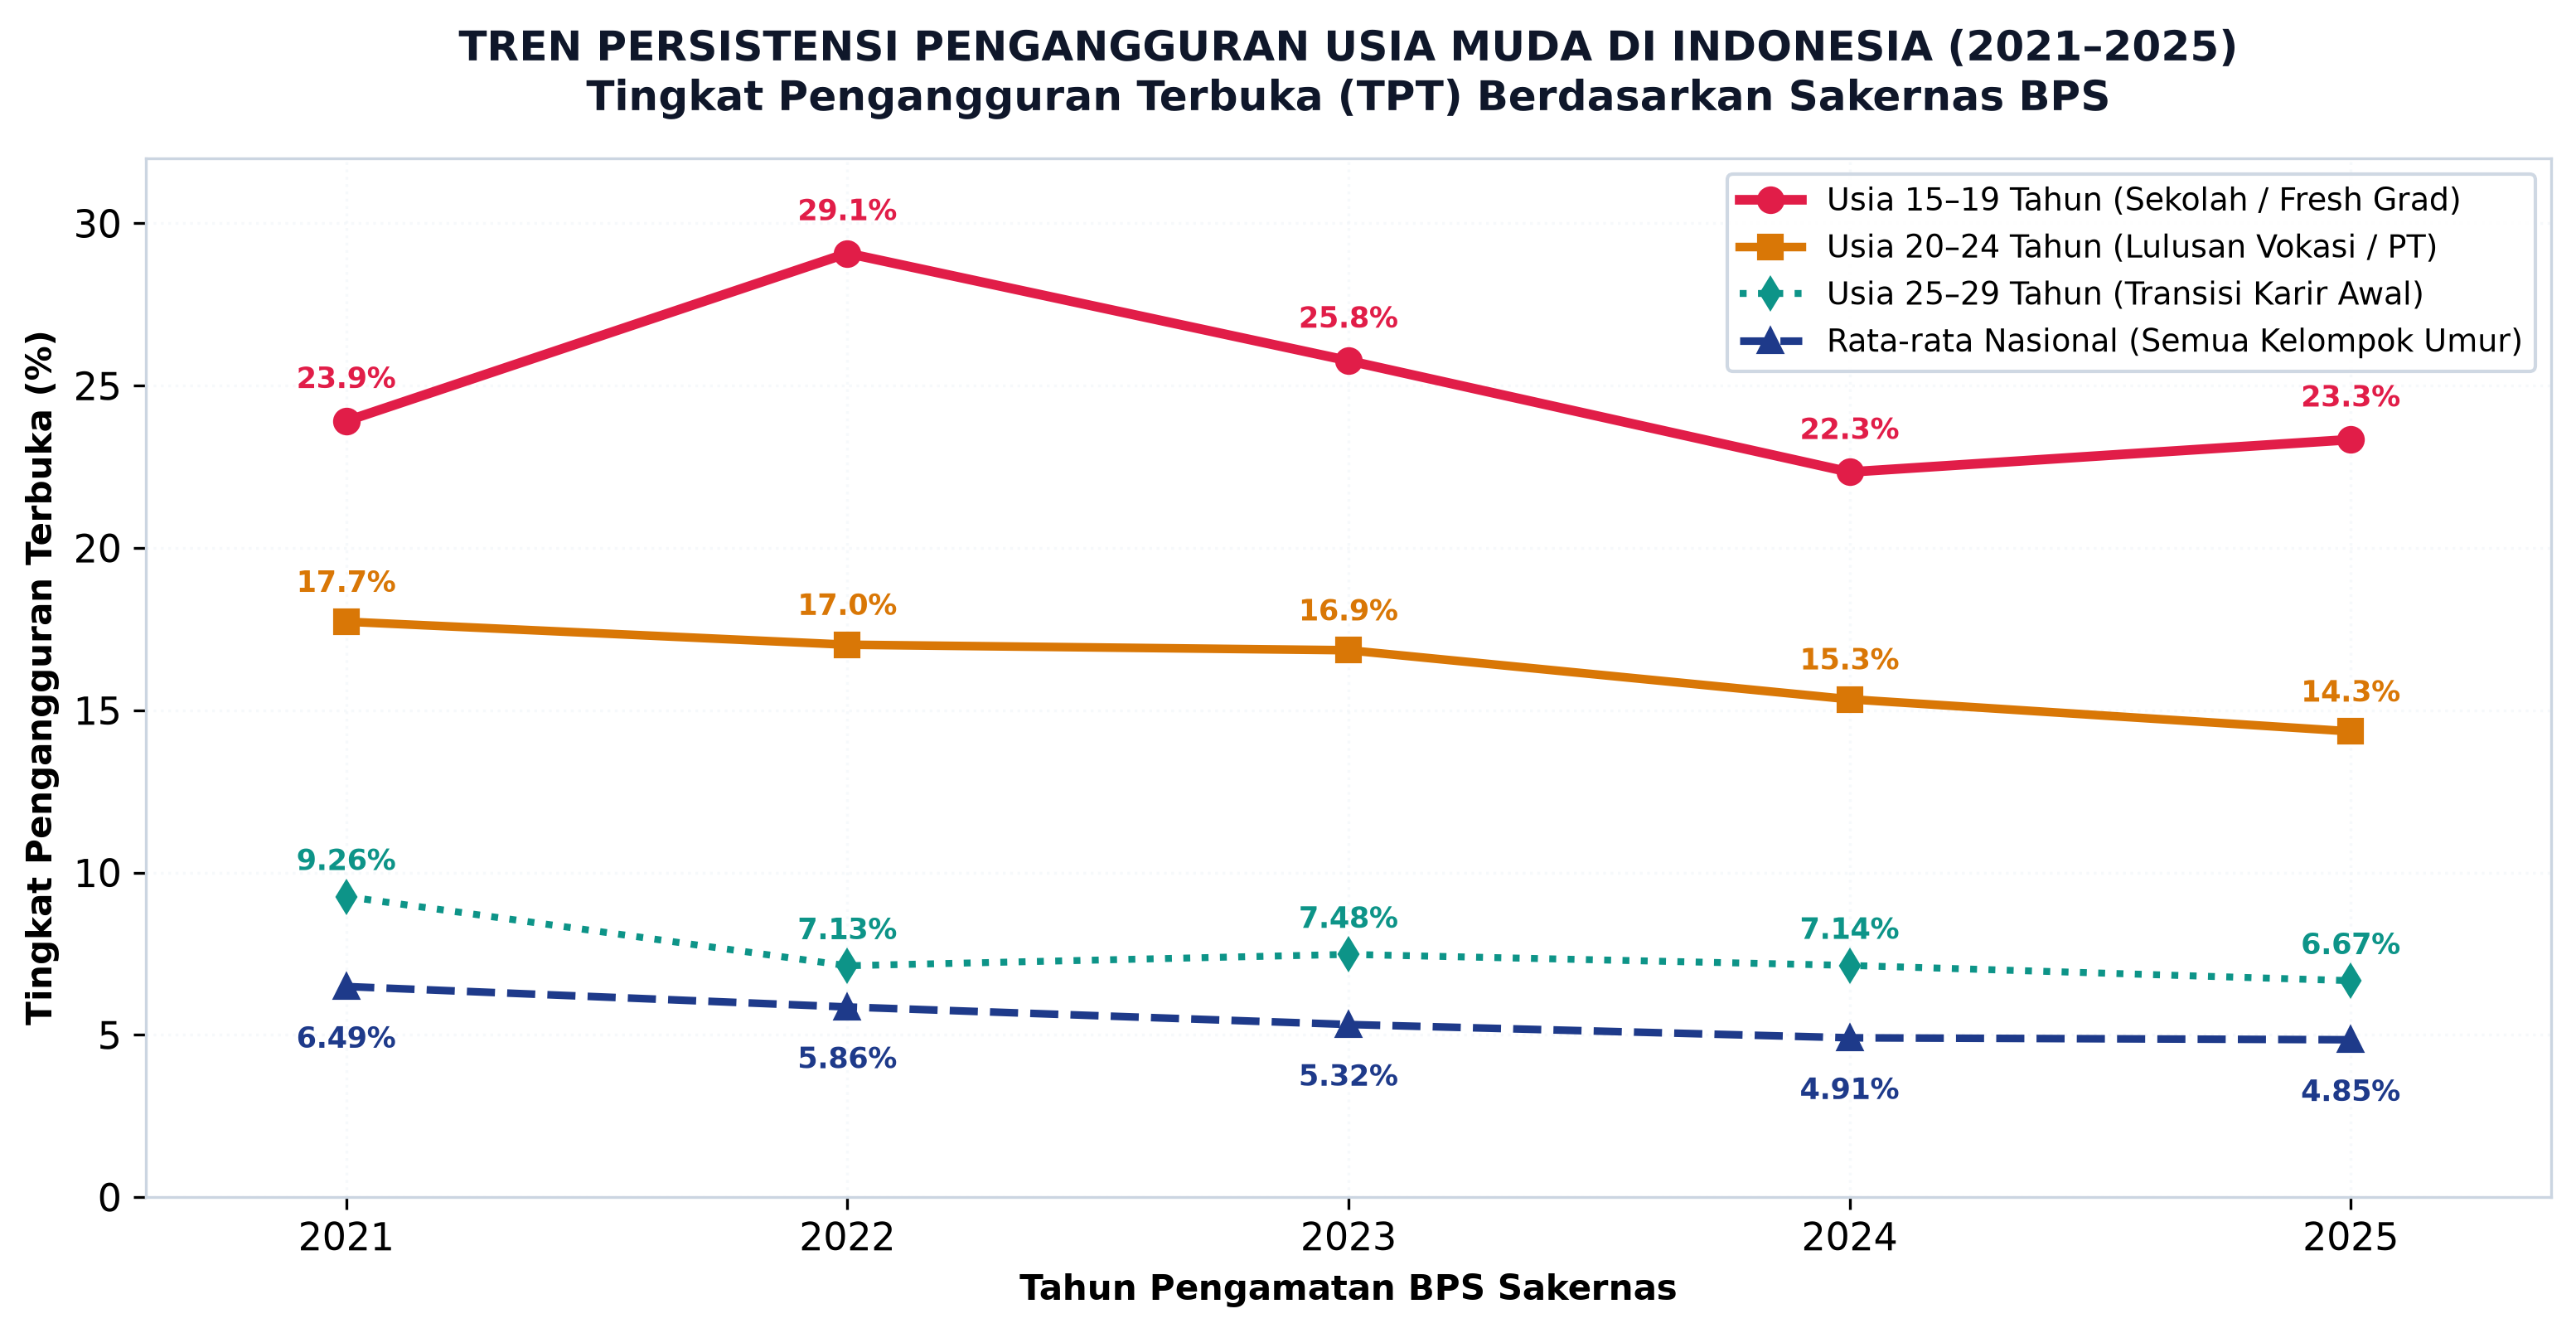

In [2]:
# Grafik 1A: Tren Persistensi Pengangguran Usia Muda (2021–2025)
years = [2021, 2022, 2023, 2024, 2025]
row_15_19 = df_age_trend[df_age_trend["Kelompok_Umur"].str.contains("15–19")].iloc[0]
row_20_24 = df_age_trend[df_age_trend["Kelompok_Umur"].str.contains("20–24")].iloc[0]
row_25_29 = df_age_trend[df_age_trend["Kelompok_Umur"].str.contains("25–29")].iloc[0]
row_total = df_age_trend[df_age_trend["Kelompok_Umur"].str.contains("Total")].iloc[0]

y_15_19 = [float(row_15_19[str(yr)]) for yr in years]
y_20_24 = [float(row_20_24[str(yr)]) for yr in years]
y_25_29 = [float(row_25_29[str(yr)]) for yr in years]
y_total = [float(row_total[str(yr)]) for yr in years]

fig1, ax1 = plt.subplots(figsize=(10.5, 5.5))
ax1.plot(years, y_15_19, marker='o', color=COLOR_CORAL, linewidth=2.8, markersize=7, label="Usia 15–19 Tahun (Sekolah / Fresh Grad)")
ax1.plot(years, y_20_24, marker='s', color=COLOR_AMBER, linewidth=2.5, markersize=6.5, label="Usia 20–24 Tahun (Lulusan Vokasi / PT)")
ax1.plot(years, y_25_29, marker='d', color=COLOR_TEAL, linewidth=2.0, markersize=6, linestyle=':', label="Usia 25–29 Tahun (Transisi Karir Awal)")
ax1.plot(years, y_total, marker='^', color=COLOR_NAVY, linewidth=2.2, markersize=6.5, linestyle='--', label="Rata-rata Nasional (Semua Kelompok Umur)")

for yr, v in zip(years, y_15_19):
    ax1.text(yr, v + 0.8, f"{v:.1f}%", ha="center", va="bottom", fontsize=8.5, weight="bold", color=COLOR_CORAL)
for yr, v in zip(years, y_20_24):
    ax1.text(yr, v + 0.7, f"{v:.1f}%", ha="center", va="bottom", fontsize=8.5, weight="bold", color=COLOR_AMBER)
for yr, v in zip(years, y_25_29):
    ax1.text(yr, v + 0.6, f"{v:.2f}%", ha="center", va="bottom", fontsize=8.5, weight="bold", color=COLOR_TEAL)
for yr, v in zip(years, y_total):
    ax1.text(yr, v - 1.2, f"{v:.2f}%", ha="center", va="top", fontsize=8.5, weight="bold", color=COLOR_NAVY)
ax1.set_title("TREN PERSISTENSI PENGANGGURAN USIA MUDA DI INDONESIA (2021–2025)\nTingkat Pengangguran Terbuka (TPT) Berdasarkan Sakernas BPS", 
              fontsize=12, weight="bold", color=COLOR_TEXT, pad=14)
ax1.set_xlabel("Tahun Pengamatan BPS Sakernas", fontsize=10, weight="bold")
ax1.set_ylabel("Tingkat Pengangguran Terbuka (%)", fontsize=10, weight="bold")
ax1.set_xlim(2020.6, 2025.4)
ax1.set_ylim(0, 32)
ax1.set_xticks(years)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right", fontsize=9, framealpha=0.92, edgecolor="#CBD5E1")
plt.tight_layout()
fig1.savefig(CHARTS_DIR / "01a_tren_pengangguran_usia_muda.svg", format="svg", bbox_inches="tight")
fig1.savefig(CHARTS_DIR / "01a_tren_pengangguran_usia_muda.png", dpi=300, bbox_inches="tight")
plt.close(fig1)
display(Image(filename=str(CHARTS_DIR / "01a_tren_pengangguran_usia_muda.png")))


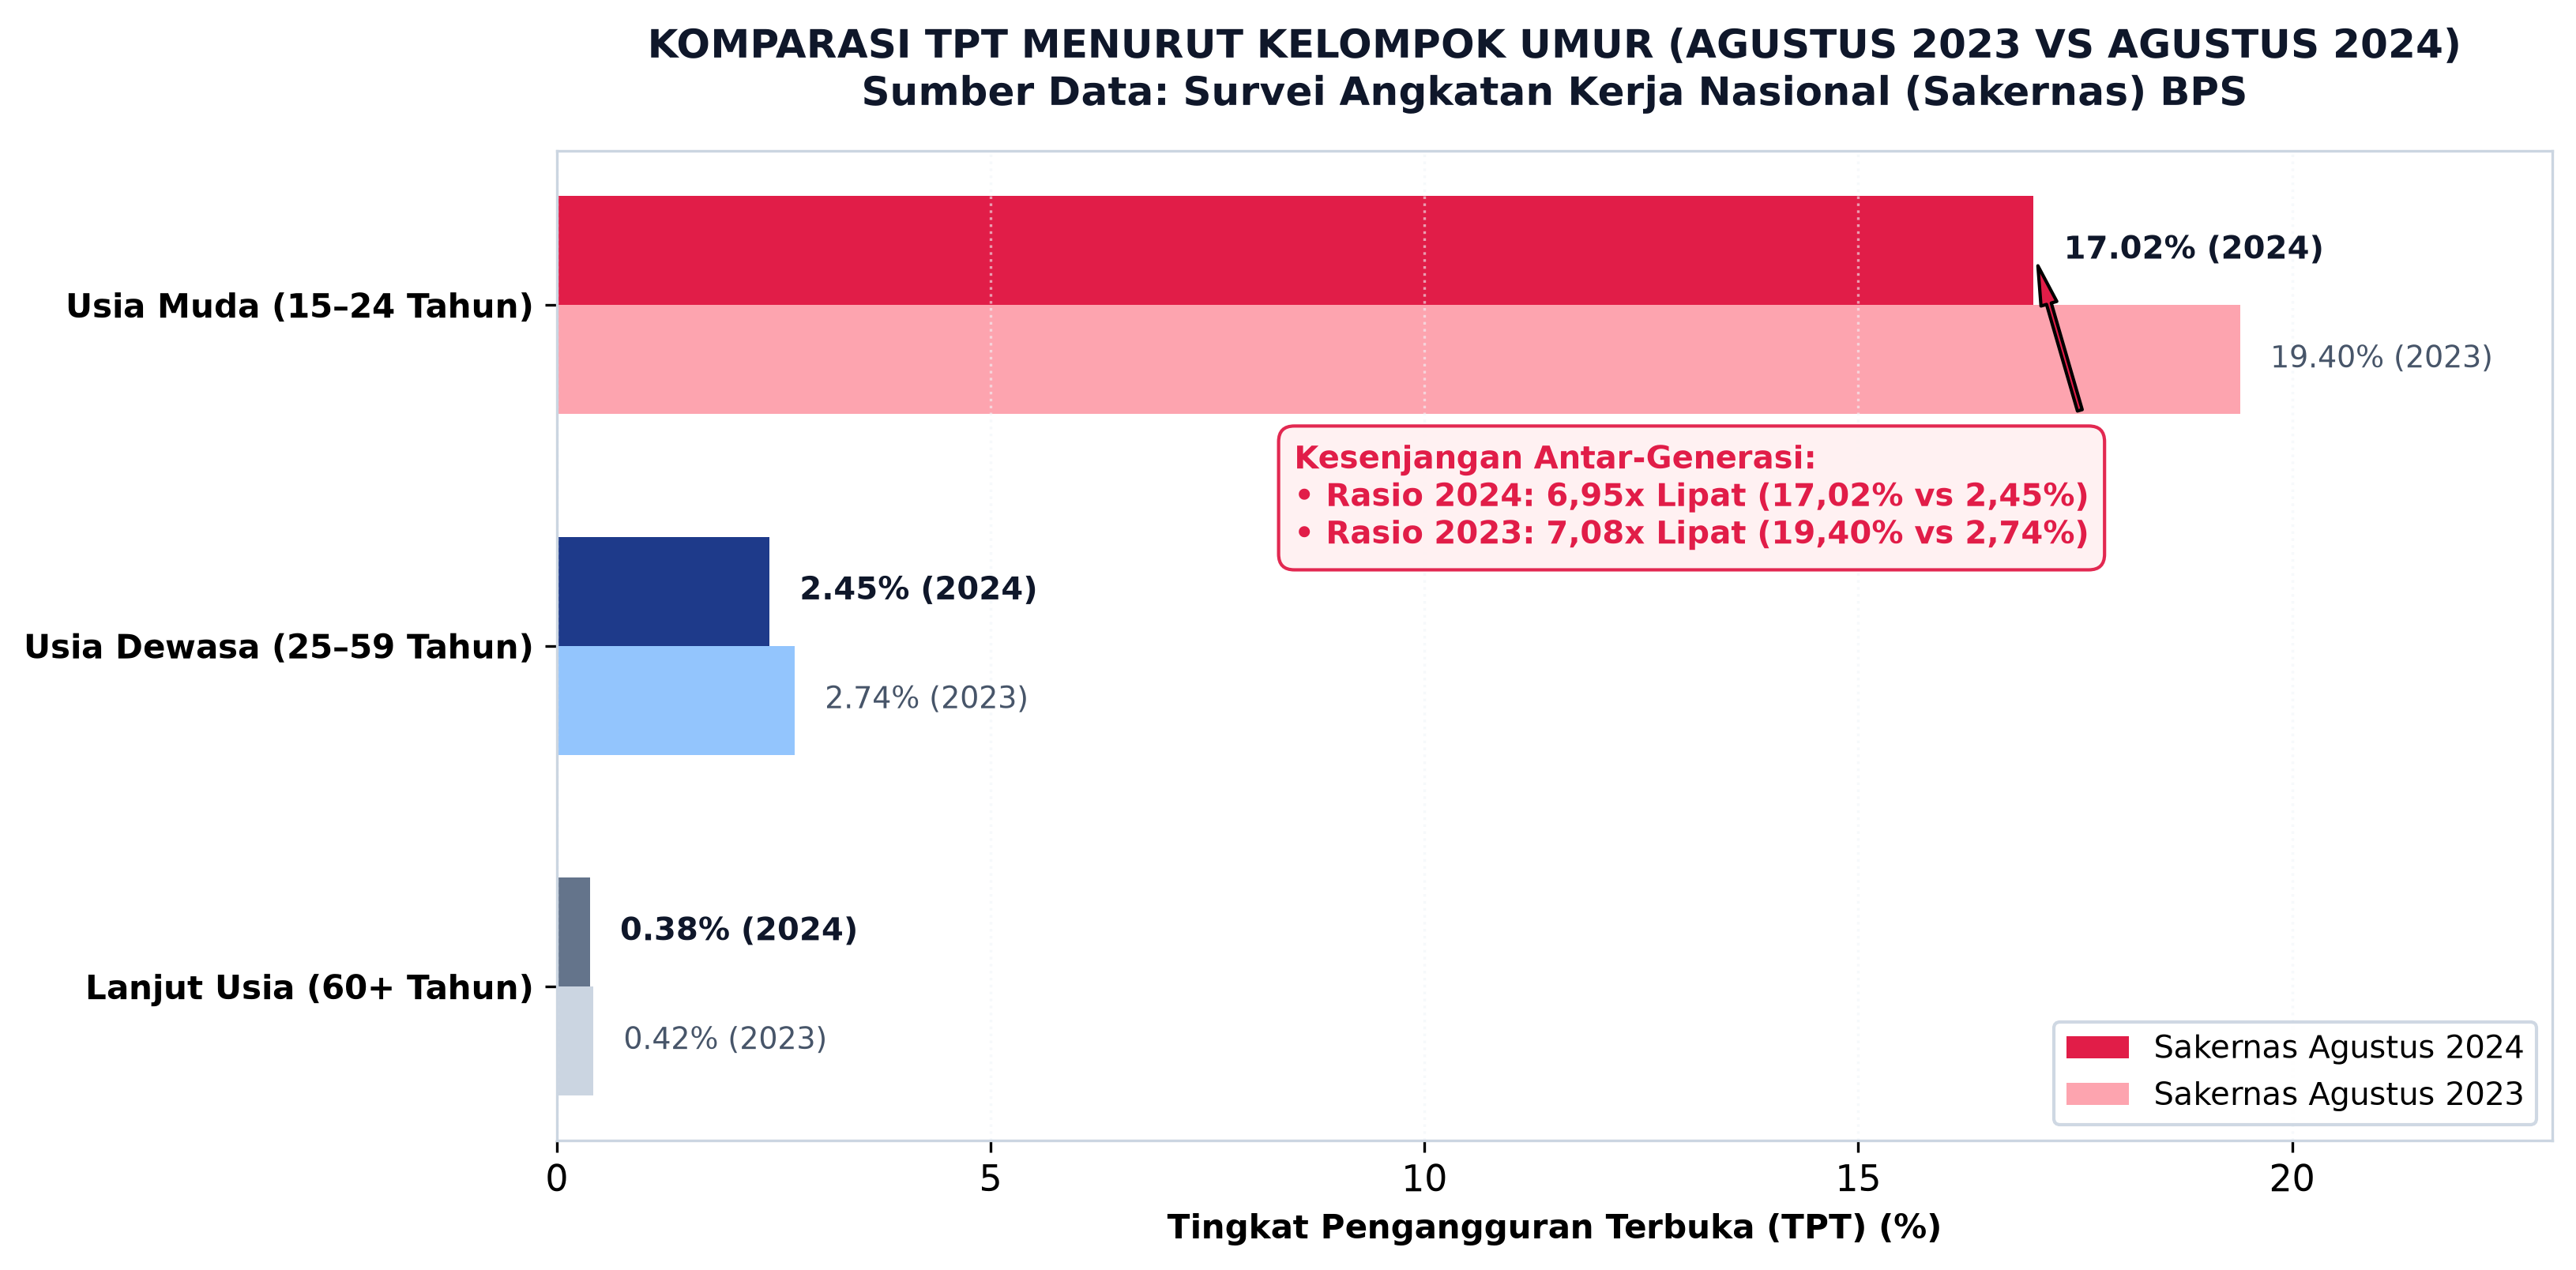

In [3]:
# Grafik 1B: Komparasi TPT Menurut Kelompok Umur (Agustus 2023 vs Agustus 2024)
df_3groups = df_youth[~df_youth["Kelompok_Umur"].str.contains("Rasio")].copy()
groups = df_3groups["Kelompok_Umur"].tolist()
tpt_23 = df_3groups["TPT_Ags2023"].tolist()
tpt_24 = df_3groups["TPT_Ags2024"].tolist()

fig2, ax2 = plt.subplots(figsize=(11, 5.5))
y_pos = np.arange(len(groups))
height = 0.32

labels_clean = ["Usia Muda (15–24 Tahun)", "Usia Dewasa (25–59 Tahun)", "Lanjut Usia (60+ Tahun)"]

bars_24 = ax2.barh(y_pos - height/2, tpt_24, height=height, color=[COLOR_CORAL, COLOR_NAVY, COLOR_SLATE],
                   edgecolor="none", label="Sakernas Agustus 2024")
bars_23 = ax2.barh(y_pos + height/2, tpt_23, height=height, color=["#FDA4AF", "#93C5FD", "#CBD5E1"],
                   edgecolor="none", label="Sakernas Agustus 2023")

for bar, val in zip(bars_24, tpt_24):
    ax2.text(bar.get_width() + 0.35, bar.get_y() + bar.get_height()/2, f"{val:.2f}% (2024)",
             va="center", ha="left", weight="bold", color=COLOR_TEXT, fontsize=9.5)
for bar, val in zip(bars_23, tpt_23):
    ax2.text(bar.get_width() + 0.35, bar.get_y() + bar.get_height()/2, f"{val:.2f}% (2023)",
             va="center", ha="left", color="#475569", fontsize=9)

ax2.annotate("Kesenjangan Antar-Generasi:\n• Rasio 2024: 6,95x Lipat (17,02% vs 2,45%)\n• Rasio 2023: 7,08x Lipat (19,40% vs 2,74%)",
             xy=(tpt_24[0], 0 - height/2), xytext=(8.5, 0.7),
             arrowprops=dict(facecolor=COLOR_CORAL, shrink=0.08, width=1.5, headwidth=5),
             bbox=dict(boxstyle="round,pad=0.5", facecolor="#FFF1F2", edgecolor=COLOR_CORAL, alpha=0.95),
             fontsize=9.5, weight="bold", color=COLOR_CORAL)

ax2.set_yticks(y_pos)
ax2.set_yticklabels(labels_clean, weight="bold", fontsize=10)
ax2.invert_yaxis()
ax2.set_xlabel("Tingkat Pengangguran Terbuka (TPT) (%)", fontsize=10, weight="bold")
ax2.set_xlim(0, 23)
ax2.grid(axis="x", linestyle=":", alpha=0.6)
ax2.set_title("KOMPARASI TPT MENURUT KELOMPOK UMUR (AGUSTUS 2023 VS AGUSTUS 2024)\nSumber Data: Survei Angkatan Kerja Nasional (Sakernas) BPS",
              fontsize=12, weight="bold", color=COLOR_TEXT, pad=14)
ax2.legend(loc="lower right", fontsize=9.5, framealpha=0.92, edgecolor="#CBD5E1")
plt.tight_layout()
fig2.savefig(CHARTS_DIR / "01b_komparasi_tpt_kelompok_umur.svg", format="svg", bbox_inches="tight")
fig2.savefig(CHARTS_DIR / "01b_komparasi_tpt_kelompok_umur.png", dpi=300, bbox_inches="tight")
fig2.savefig(CHARTS_DIR / "01_krisis_pengangguran_usia_muda.svg", format="svg", bbox_inches="tight")
fig2.savefig(CHARTS_DIR / "01_krisis_pengangguran_usia_muda.png", dpi=300, bbox_inches="tight")
plt.close(fig2)
display(Image(filename=str(CHARTS_DIR / "01b_komparasi_tpt_kelompok_umur.png")))


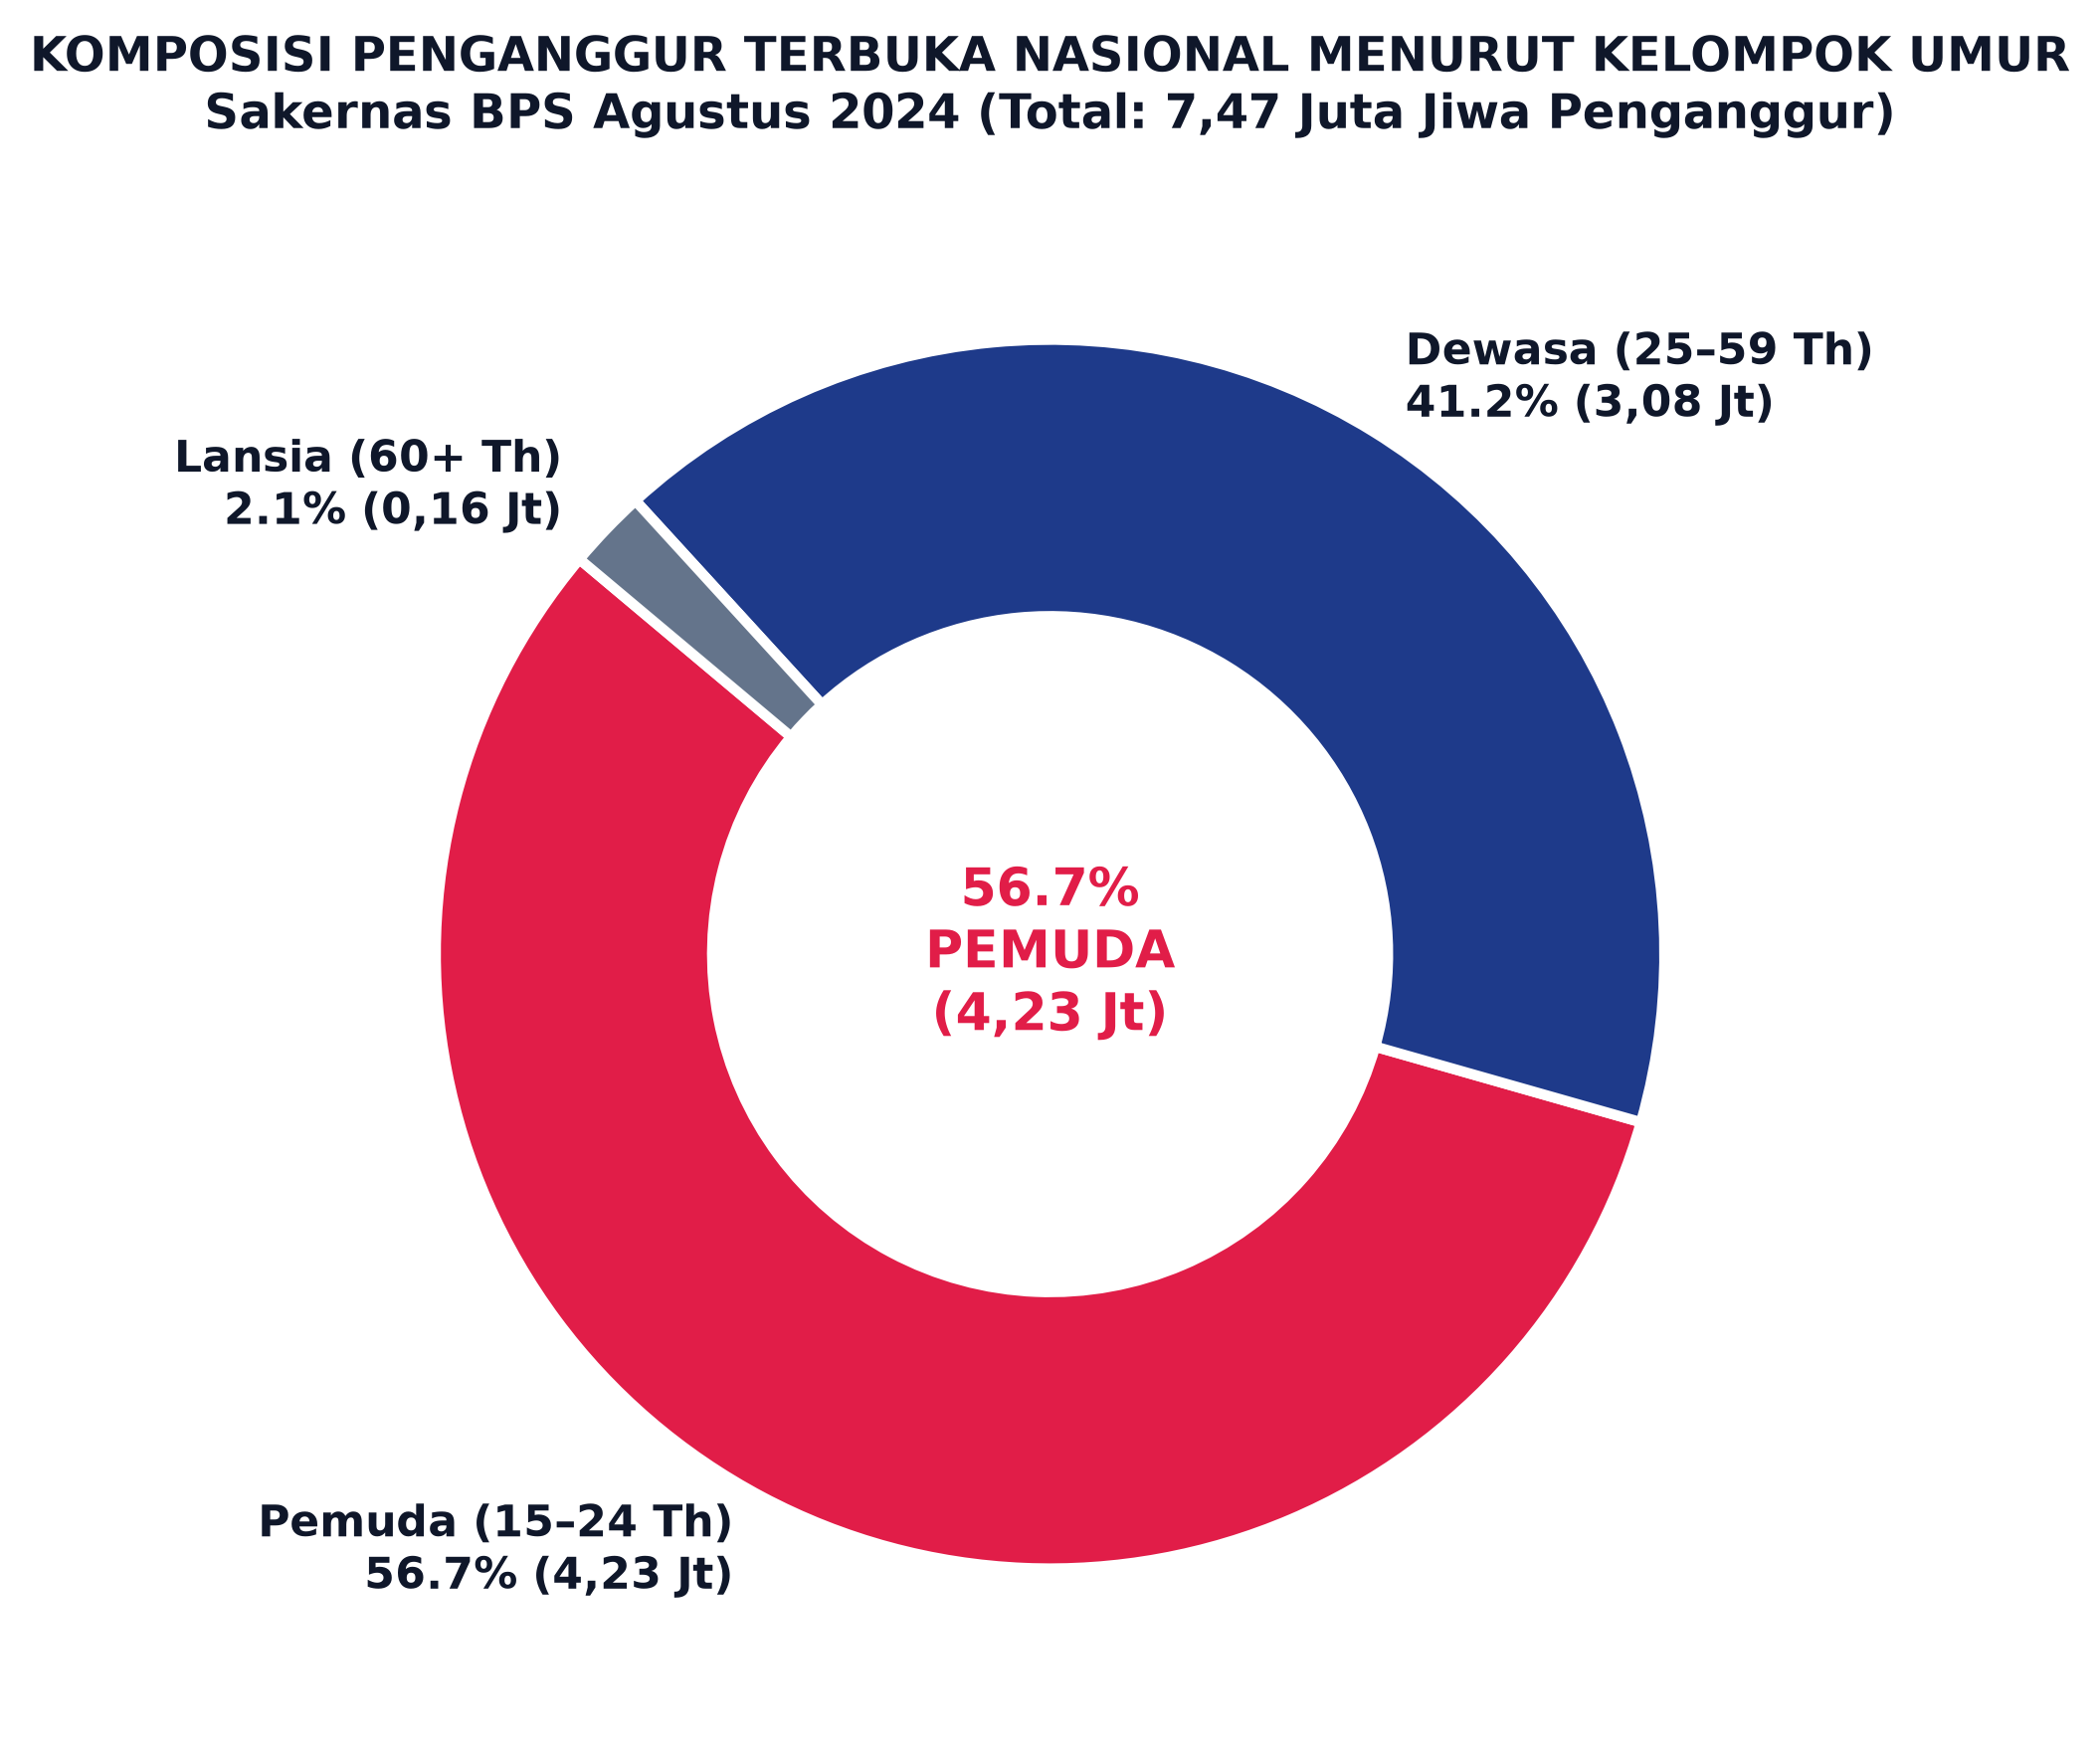

In [4]:
# Grafik 1C: Komposisi Penganggur Terbuka Menurut Kelompok Umur (Agustus 2024)
df_3groups = df_youth[~df_youth["Kelompok_Umur"].str.contains("Rasio")].copy()
shares = df_3groups["Share_Penganggur_%"].tolist()
labels_pie = [f"Pemuda (15–24 Th)\n{shares[0]:.1f}% (4,23 Jt)",
              f"Dewasa (25–59 Th)\n{shares[1]:.1f}% (3,08 Jt)",
              f"Lansia (60+ Th)\n{shares[2]:.1f}% (0,16 Jt)"]
pie_colors = [COLOR_CORAL, COLOR_NAVY, COLOR_SLATE]

fig3, ax3 = plt.subplots(figsize=(8.5, 6))
wedges, texts = ax3.pie(shares, labels=labels_pie, colors=pie_colors, startangle=140,
                        wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2.5),
                        textprops=dict(weight="bold", color=COLOR_TEXT, fontsize=10.5))

ax3.text(0, 0, f"{shares[0]:.1f}%\nPEMUDA\n(4,23 Jt)", ha="center", va="center", fontsize=12.5, weight="bold", color=COLOR_CORAL)
ax3.set_title("KOMPOSISI PENGANGGUR TERBUKA NASIONAL MENURUT KELOMPOK UMUR\nSakernas BPS Agustus 2024 (Total: 7,47 Juta Jiwa Penganggur)",
              fontsize=11.5, weight="bold", color=COLOR_TEXT, pad=14)

plt.tight_layout()
fig3.savefig(CHARTS_DIR / "01c_komposisi_penganggur_usia.svg", format="svg", bbox_inches="tight")
fig3.savefig(CHARTS_DIR / "01c_komposisi_penganggur_usia.png", dpi=300, bbox_inches="tight")
plt.close(fig3)
display(Image(filename=str(CHARTS_DIR / "01c_komposisi_penganggur_usia.png")))


## Bab 2: The Diploma Paradox : Anomali Pengangguran Terdidik & Jembatan Vokasi

Dalam diskursus ketenagakerjaan, pendidikan formal kerap diposisikan sebagai jaminan mobilitas ekonomi vertikal. Semakin tinggi ijazah yang dimiliki, semakin besar peluang seseorang untuk langsung terserap di dunia usaha.

Namun, data resmi BPS justru memperlihatkan hubungan terbalik yang mencengangkan: **pengangguran terbuka tertinggi justru berada pada lulusan sekolah kejuruan dan perguruan tinggi, sementara lulusan berpendidikan rendah mencatat angka terendah**.

### Fakta Data BPS (Agustus 2024):
* **SMK Kejuruan:** TPT sebesar **6,81%** (Peringkat tertinggi di antara seluruh jenjang pendidikan).
* **SMA Umum:** TPT sebesar **6,69%**.
* **Universitas (S1+):** TPT sebesar **5,33%** (Berada di atas rata-rata nasional 4,91% dan mengalami tren peningkatan dari 4,80% pada 2022).
* **Diploma I/II/III:** TPT sebesar **4,27%**.
* **SMP:** TPT sebesar **4,10%**.
* **SD ke Bawah:** TPT sebesar **1,92%** (Peringkat terendah).
* Rasio kesenjangan pengangguran lulusan SMK terhadap lulusan SD mencapai **3,55 kali lipat**, sedangkan lulusan universitas mencapai **2,78 kali lipat**.

### Analisis Tiga Faktor Pendorong Paradoks:
1. **Upah Reservasi (*Reservation Wage*) dan Kemampuan Menunggu:** Penduduk berpendidikan SD ke bawah tidak memiliki bantalan finansial keluarga yang memadai, sehingga mereka tidak sanggup menganggur dan terpaksa menyerap pekerjaan apa pun di sektor informal atau sektor pertanian subsisten. Sebaliknya, lulusan sarjana dan SMK memiliki ekspektasi upah tertentu dan daya tahan ekonomi untuk menunggu lowongan formal yang sesuai.
2. **Kesenjangan Keterampilan (*Skill Mismatch*):** Kurikulum vokasi dan perguruan tinggi kerap tertinggal dari akselerasi otomasi dan digitalisasi industri manufaktur/jasa modern. Terjadi ketidaksesuaian antara kompetensi praktis yang diajarkan dengan kebutuhan riil industri.
3. **Pertumbuhan Minim Serapan Formal (*Jobless Growth*):** Peningkatan TPT sarjana dari 4,80% (2022) menjadi 5,33% (2024) mengindikasikan bahwa laju kelulusan sarjana baru melampaui kapasitas penyerapan industri padat modal formal.


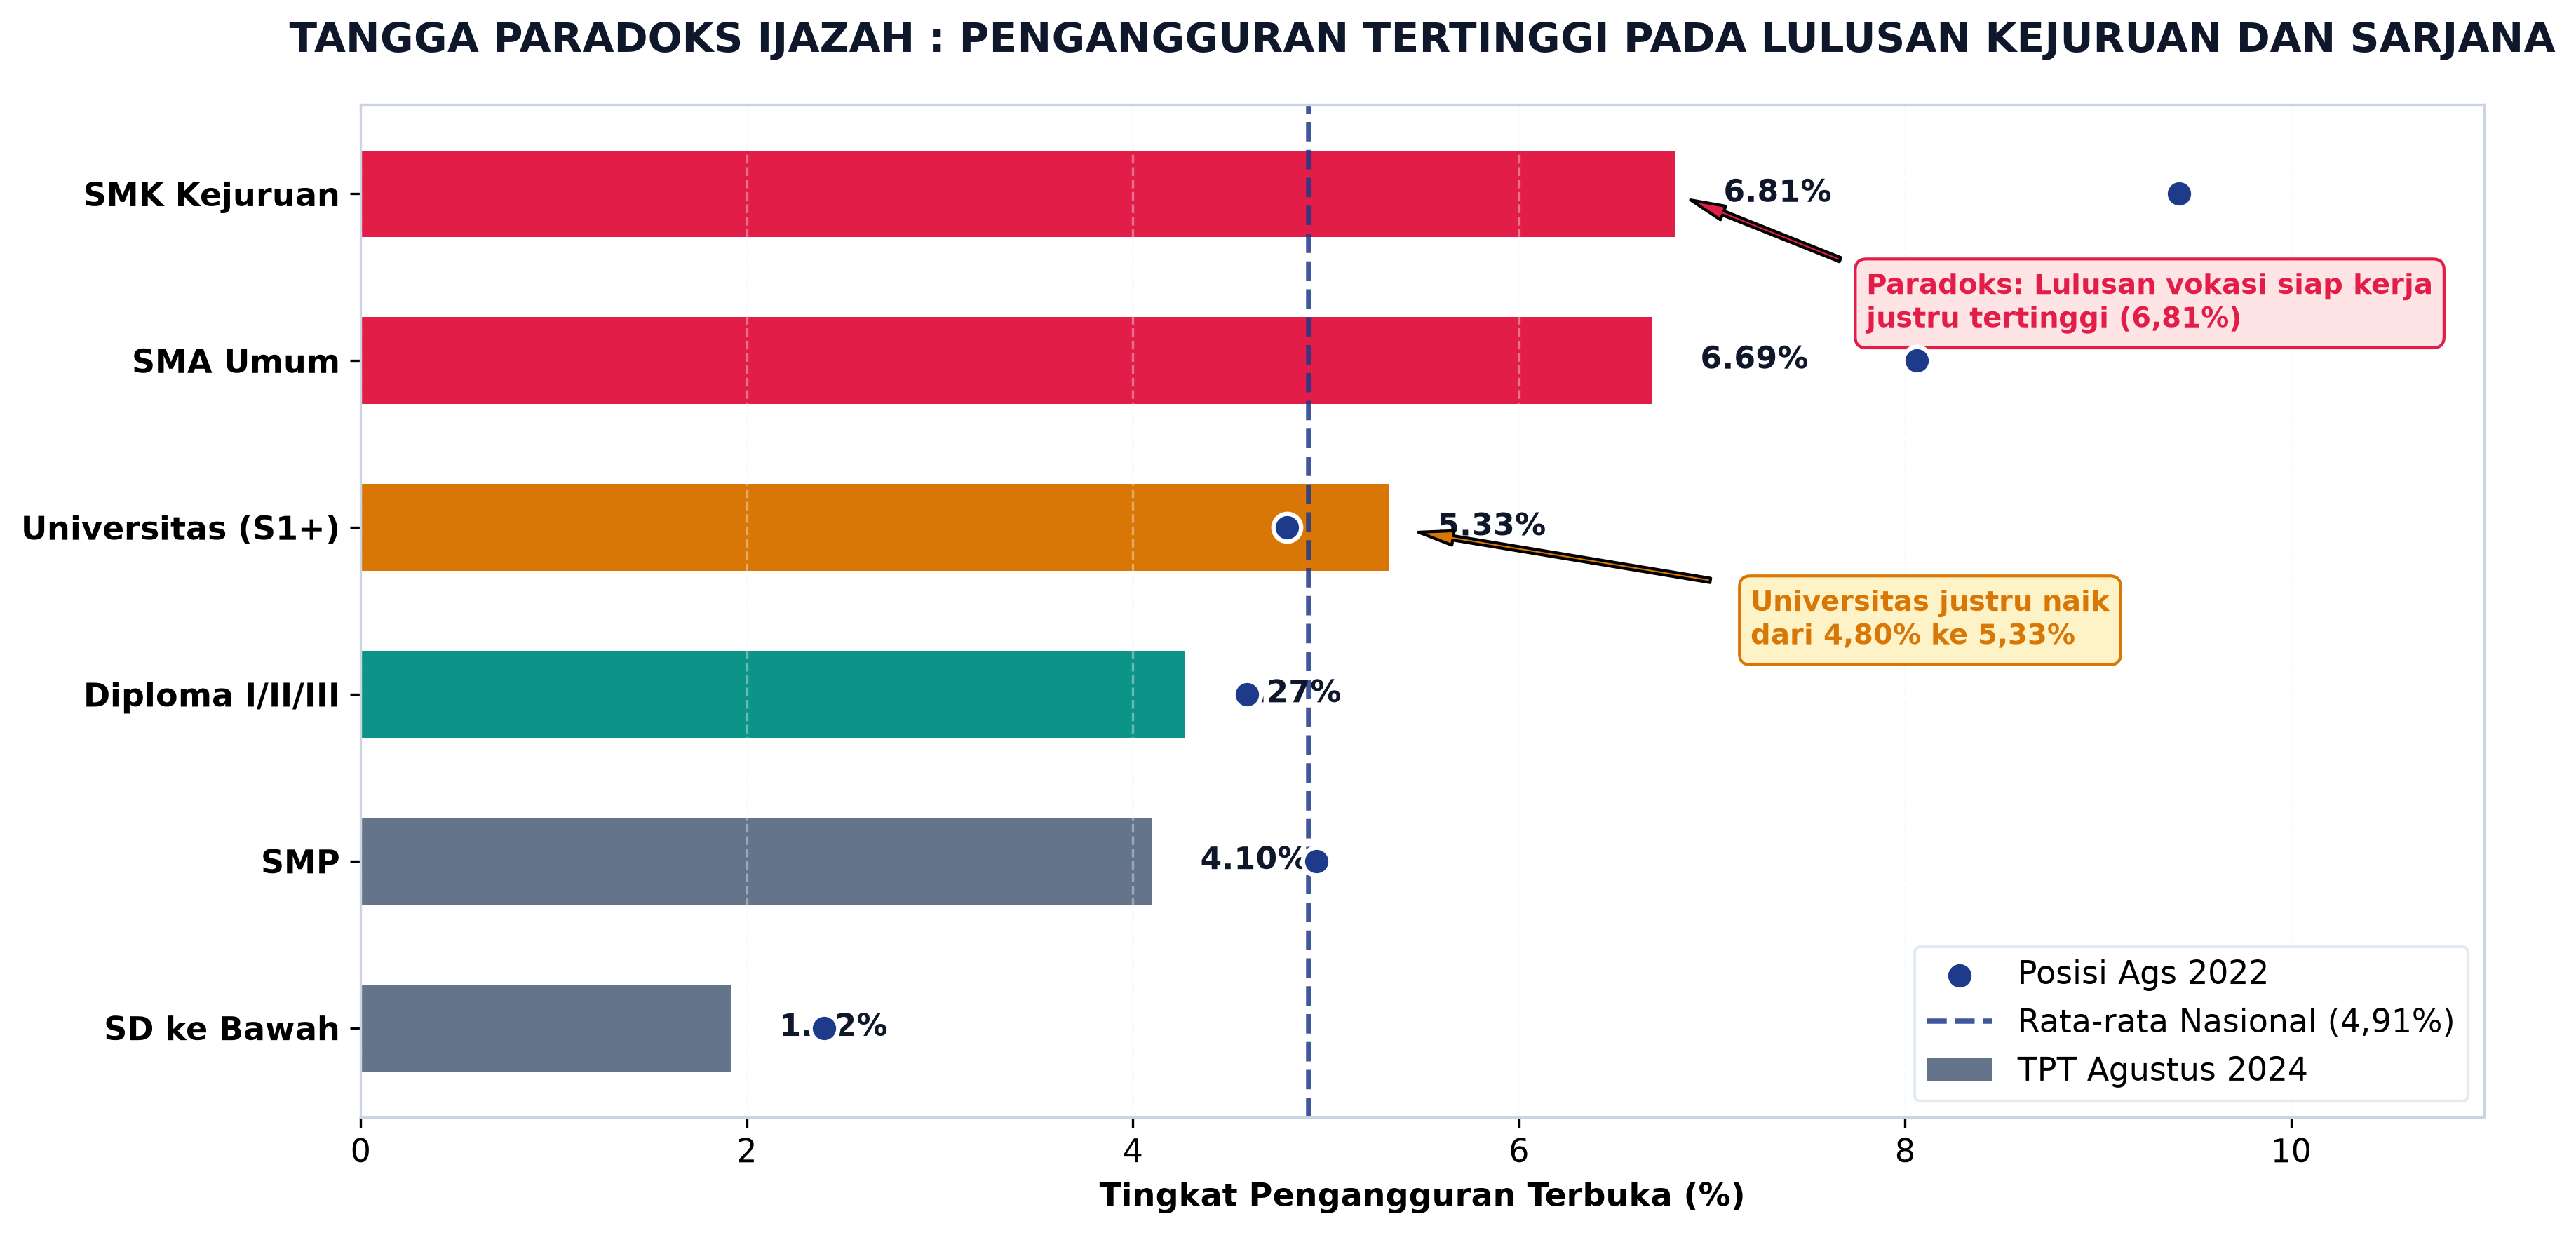

In [5]:
# Grafik 2: Tangga Paradoks Ijazah — Anatomi Pengangguran Terdidik
fig, ax = plt.subplots(figsize=(12, 6))

pendidikan_order = ["SD ke Bawah", "SMP", "Diploma I/II/III", "Universitas (S1+)", "SMA Umum", "SMK Kejuruan"]
tpt_2024 = [1.92, 4.10, 4.27, 5.33, 6.69, 6.81]
tpt_2022 = [2.40, 4.95, 4.59, 4.80, 8.06, 9.42]

y_pos = np.arange(len(pendidikan_order))

# Differentiated bar colors based on paradox severity
bar_colors = [COLOR_SLATE, COLOR_SLATE, COLOR_TEAL, COLOR_AMBER, COLOR_CORAL, COLOR_CORAL]

bars = ax.barh(y_pos, tpt_2024, height=0.52, color=bar_colors, edgecolor="none", label="TPT Agustus 2024")

# Plot 2022 markers for trajectory comparison
ax.scatter(tpt_2022, y_pos, color=COLOR_NAVY, s=90, zorder=5, label="Posisi Ags 2022", edgecolors="white", linewidth=1.5)

# National Average Reference Line
ax.axvline(4.91, color=COLOR_NAVY, linestyle="--", linewidth=1.8, label="Rata-rata Nasional (4,91%)", alpha=0.85)

ax.set_yticks(y_pos)
ax.set_yticklabels(pendidikan_order, weight="bold")
ax.set_xlabel("Tingkat Pengangguran Terbuka (%)", weight="bold")
ax.set_xlim(0, 11)
ax.set_title("TANGGA PARADOKS IJAZAH : PENGANGGURAN TERTINGGI PADA LULUSAN KEJURUAN DAN SARJANA", 
             fontsize=14, weight="bold", color=COLOR_TEXT, pad=18)
ax.grid(axis="x", alpha=0.4)

# Value annotations
for idx, (val24, val22) in enumerate(zip(tpt_2024, tpt_2022)):
    delta = val24 - val22
    delta_str = f"({delta:+.2f})" if delta != 0 else ""
    ax.text(val24 + 0.25, idx, f"{val24:.2f}%", va="center", weight="bold", color=COLOR_TEXT, fontsize=10.5)

# Annotation callouts
ax.annotate("Paradoks: Lulusan vokasi siap kerja\njustru tertinggi (6,81%)",
            xy=(6.81, 5), xytext=(7.8, 4.2),
            arrowprops=dict(facecolor=COLOR_CORAL, shrink=0.08, width=1.5, headwidth=5),
            bbox=dict(boxstyle="round,pad=0.4", facecolor="#FFE4E6", edgecolor=COLOR_CORAL),
            fontsize=9.5, weight="bold", color=COLOR_CORAL)

ax.annotate("Universitas justru naik\ndari 4,80% ke 5,33%",
            xy=(5.33, 3), xytext=(7.2, 2.3),
            arrowprops=dict(facecolor=COLOR_AMBER, shrink=0.08, width=1.5, headwidth=5),
            bbox=dict(boxstyle="round,pad=0.4", facecolor="#FEF3C7", edgecolor=COLOR_AMBER),
            fontsize=9.5, weight="bold", color=COLOR_AMBER)

ax.legend(loc="lower right", frameon=True, framealpha=0.9, edgecolor="#E2E8F0")
plt.tight_layout()
fig.savefig(CHARTS_DIR / "02_paradoks_pengangguran_terdidik.svg", format="svg", bbox_inches="tight")
fig.savefig(CHARTS_DIR / "02_paradoks_pengangguran_terdidik.png", dpi=300, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(CHARTS_DIR / "02_paradoks_pengangguran_terdidik.png")))


## Bab 3: The Spatial Fracture : Disparitas Regional & Ilusi Pengangguran Rendah

Mengevaluasi pasar kerja Indonesia hanya berdasarkan agregat nasional ibarat mengukur kedalaman danau dari rata-ratanya: mengabaikan palung tajam di dasar perairan. Data 38 provinsi di Indonesia memperlihatkan disparitas spasial yang sangat tajam hingga **5,11 kali lipat**.

### Rentang Disparitas 2024:
* **Provinsi TPT Tertinggi:** Didominasi oleh pusat metropolitan dan manufaktur: Jawa Barat (6,75%), Banten (6,68%), Papua Barat Daya (6,48%), Papua (6,48%), dan Kepulauan Riau (6,39%).
* **Provinsi TPT Terendah:** Berada di kawasan timur dan agraris: Papua Pegunungan (1,32%), Bali (1,79%), Sulawesi Barat (2,68%), dan Nusa Tenggara Barat (2,73%).

### Membongkar Ilusi Angka Rendah via Sektor Informal:
Apakah angka pengangguran 1,32% di Papua Pegunungan atau 2,73% di NTB mencerminkan kesejahteraan ekonomi masyarakatnya?

Analisis ekonometrika membongkar ilusi ini secara tuntas:
* Ditemukan **korelasi negatif yang sangat kuat ($r = -0,782$)** antara angka TPT dengan persentase pekerja sektor informal.
* Sebaliknya, terdapat **korelasi positif ($r = +0,641$)** antara TPT dengan tingkat upah buruh regional.

Daerah dengan angka TPT terendah di Indonesia justru merupakan kawasan dengan tingkat informalitas ekstrem (Papua Pegunungan 95,8% informal, NTB 72,8% informal). Di wilayah ini, masyarakat miskin tidak memiliki pilihan jaring pengaman, sehingga mereka terpaksa bekerja apa saja di sektor pertanian subsisten berupah rendah (*informal shelter*). 

Sebaliknya, provinsi berupah tinggi di Pulau Jawa menjadi magnet urbanisasi tenaga kerja berpendidikan, sehingga menciptakan antrean pencari kerja formal (*labor queuing*) yang tercatat sebagai pengangguran terbuka.


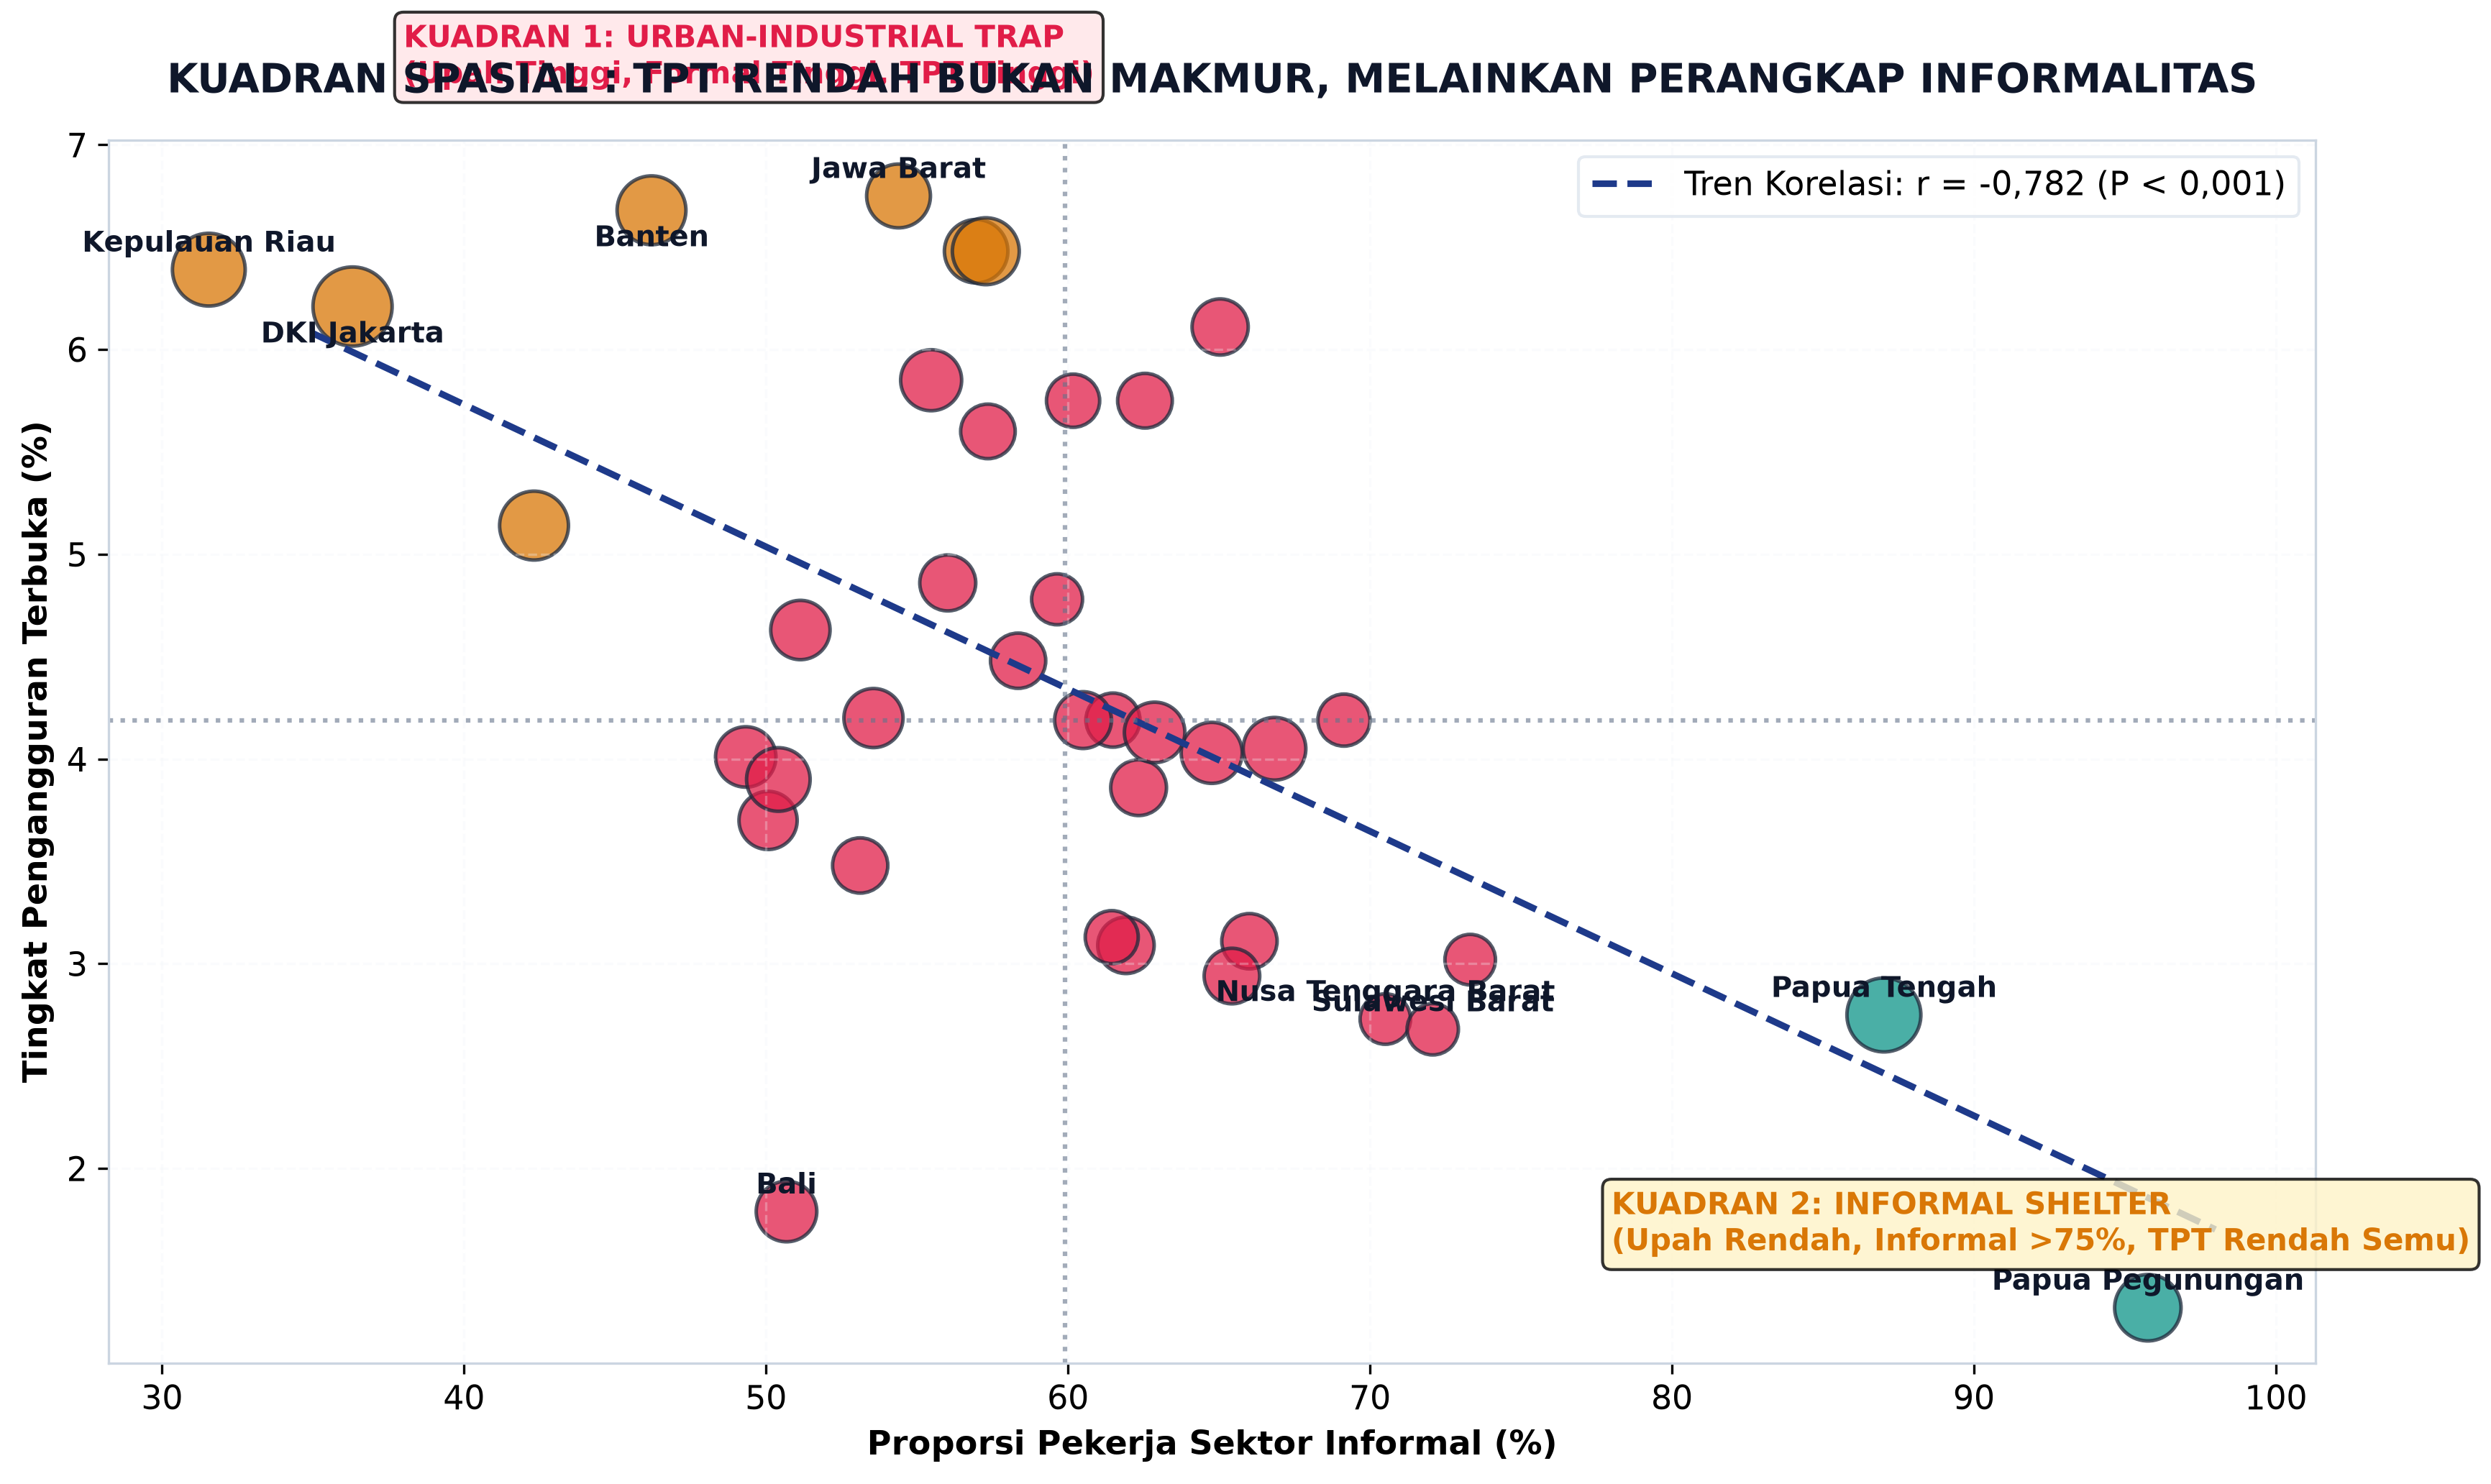

In [6]:
# Grafik 3: Kuadran Ilusi Pengangguran Rendah vs Perangkap Informalitas
fig, ax = plt.subplots(figsize=(12, 7))

# Filter provinces (exclude national total)
df_prov = df_clusters[df_clusters["Provinsi"] != "Indonesia"].copy()

x_inf = df_prov["Informal_Ags2024"]
y_tpt = df_prov["TPT_Total_Ags2024"]
wage = df_prov["Upah_Total_Ags2024"]

# Size proportional to wage (divided by 15000 for visibility)
bubble_sizes = (wage / 100000) * 12

# Color by cluster
cluster_color_map = {
    0: COLOR_CORAL,  # Urban-Industrial Trap
    1: COLOR_AMBER,  # Agrarian-Informal Shelter
    2: COLOR_TEAL    # Balanced Transition
}
point_colors = [cluster_color_map[c] for c in df_prov["Klaster"]]

scatter = ax.scatter(x_inf, y_tpt, s=bubble_sizes, c=point_colors, alpha=0.75, edgecolors="#1E293B", linewidth=1.2)

# Regression line
m, b = np.polyfit(x_inf, y_tpt, 1)
x_line = np.linspace(35, 98, 100)
ax.plot(x_line, m*x_line + b, color=COLOR_NAVY, linestyle="--", linewidth=2.2, label=f"Tren Korelasi: r = -0,782 (P < 0,001)")

# Quadrant Dividers at Medians
med_x = x_inf.median()
med_y = y_tpt.median()
ax.axvline(med_x, color=COLOR_SLATE, linestyle=":", alpha=0.6)
ax.axhline(med_y, color=COLOR_SLATE, linestyle=":", alpha=0.6)

# Label key outlier provinces
outliers_to_label = [
    "Jawa Barat", "Banten", "DKI Jakarta", "Kepulauan Riau", 
    "Papua Pegunungan", "Bali", "Nusa Tenggara Barat", "Sulawesi Barat", "Papua Tengah"
]
for _, row in df_prov.iterrows():
    if row["Provinsi"] in outliers_to_label:
        offset_y = 0.18 if row["Provinsi"] not in ["DKI Jakarta", "Banten"] else -0.28
        ax.annotate(row["Provinsi"], (row["Informal_Ags2024"], row["TPT_Total_Ags2024"]),
                    xytext=(0, 6 if offset_y > 0 else -12), textcoords="offset points",
                    ha="center", fontsize=9.5, weight="bold", color=COLOR_TEXT)

# Quadrant Titles
ax.text(38, 7.3, "KUADRAN 1: URBAN-INDUSTRIAL TRAP\n(Upah Tinggi, Formal Tinggi, TPT Tinggi)", 
        fontsize=10, weight="bold", color=COLOR_CORAL, bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFE4E6", alpha=0.8))
ax.text(78, 1.6, "KUADRAN 2: INFORMAL SHELTER\n(Upah Rendah, Informal >75%, TPT Rendah Semu)", 
        fontsize=10, weight="bold", color=COLOR_AMBER, bbox=dict(boxstyle="round,pad=0.3", facecolor="#FEF3C7", alpha=0.8))

ax.set_xlabel("Proporsi Pekerja Sektor Informal (%)", weight="bold")
ax.set_ylabel("Tingkat Pengangguran Terbuka (%)", weight="bold")
ax.set_title("KUADRAN SPASIAL : TPT RENDAH BUKAN MAKMUR, MELAINKAN PERANGKAP INFORMALITAS", 
             fontsize=13.5, weight="bold", color=COLOR_TEXT, pad=16)

ax.grid(True, alpha=0.3)
ax.legend(loc="upper right", frameon=True, framealpha=0.9, edgecolor="#E2E8F0")

plt.tight_layout()
fig.savefig(CHARTS_DIR / "03_disparitas_regional_dan_ilusi_informal.svg", format="svg", bbox_inches="tight")
fig.savefig(CHARTS_DIR / "03_disparitas_regional_dan_ilusi_informal.png", dpi=300, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(CHARTS_DIR / "03_disparitas_regional_dan_ilusi_informal.png")))


## Bab 4: The Recovery Drift : Guncangan Pandemi & Asimetri Pemulihan 2017–2024

Pasar tenaga kerja adalah cermin paling sensitif terhadap guncangan makroekonomi. Melalui panel data seimbang 34 provinsi selama 8 tahun berturut-turut (2017–2024), kita dapat melacak elastisitas daya tahan ketenagakerjaan daerah sebelum, saat, dan sesudah krisis global COVID-19.

### Kronologi Siklus 8 Tahun Sakernas BPS:
1. **Fase Stabilitas Normal (2017–2019):** TPT nasional bergerak melandai teratur dari 5,50% (2017) menjadi 5,23% (2019).
2. **Puncak Syok Eksogen (2020):** Pandemi COVID-19 memicu lonjakan drastis TPT ke angka **7,07%** (+1,84 persen poin atau setara dengan pertambahan 2,67 juta penganggur baru dalam tempo setahun).
3. **Fase Pemulihan Bertahap (2021–2023):** Pelonggaran mobilitas menurunkan angka pengangguran ke 6,49% (2021), 5,86% (2022), dan 5,32% (2023).
4. **Normalisasi Penuh (2024):** TPT nasional menyentuh 4,91% (berada 0,32 poin di bawah level pra-pandemi 2019).

### Asimetri Dua Kecepatan Pemulihan Antar-Provinsi:
Meskipun angka nasional telah pulih, laju pemulihan di tingkat daerah bergerak secara asimetris:
* **Kelompok Pemulihan Cepat (*Fast Recoverers*):** Provinsi seperti Riau (turun -2,06 poin dibanding 2019), Banten (-1,43 poin), dan Jawa Barat (-1,29 poin) mengalami percepatan penyerapan kembali tenaga kerja seiring reaktivasi rantai pasok industri. Bali yang sempat terpuruk akibat kelumpuhan pariwisata (melonjak ke 5,63% pada 2020) berhasil membalikkan keadaan menjadi 1,79% pada 2024.
* **Kelompok Pemulihan Tertinggal (*Lagging Recoverers*):** Beberapa provinsi justru mencatatkan angka pengangguran 2024 yang lebih tinggi dibandingkan sebelum pandemi 2019: Jawa Timur (+0,37 poin), DI Yogyakarta (+0,30 poin), dan Papua (+2,97 poin). Fakta ini membuktikan adanya efek luka persisten (*hysteresis*) di mana sektor formal di daerah tertentu belum sanggup kembali ke kapasitas serapan prapandemi.


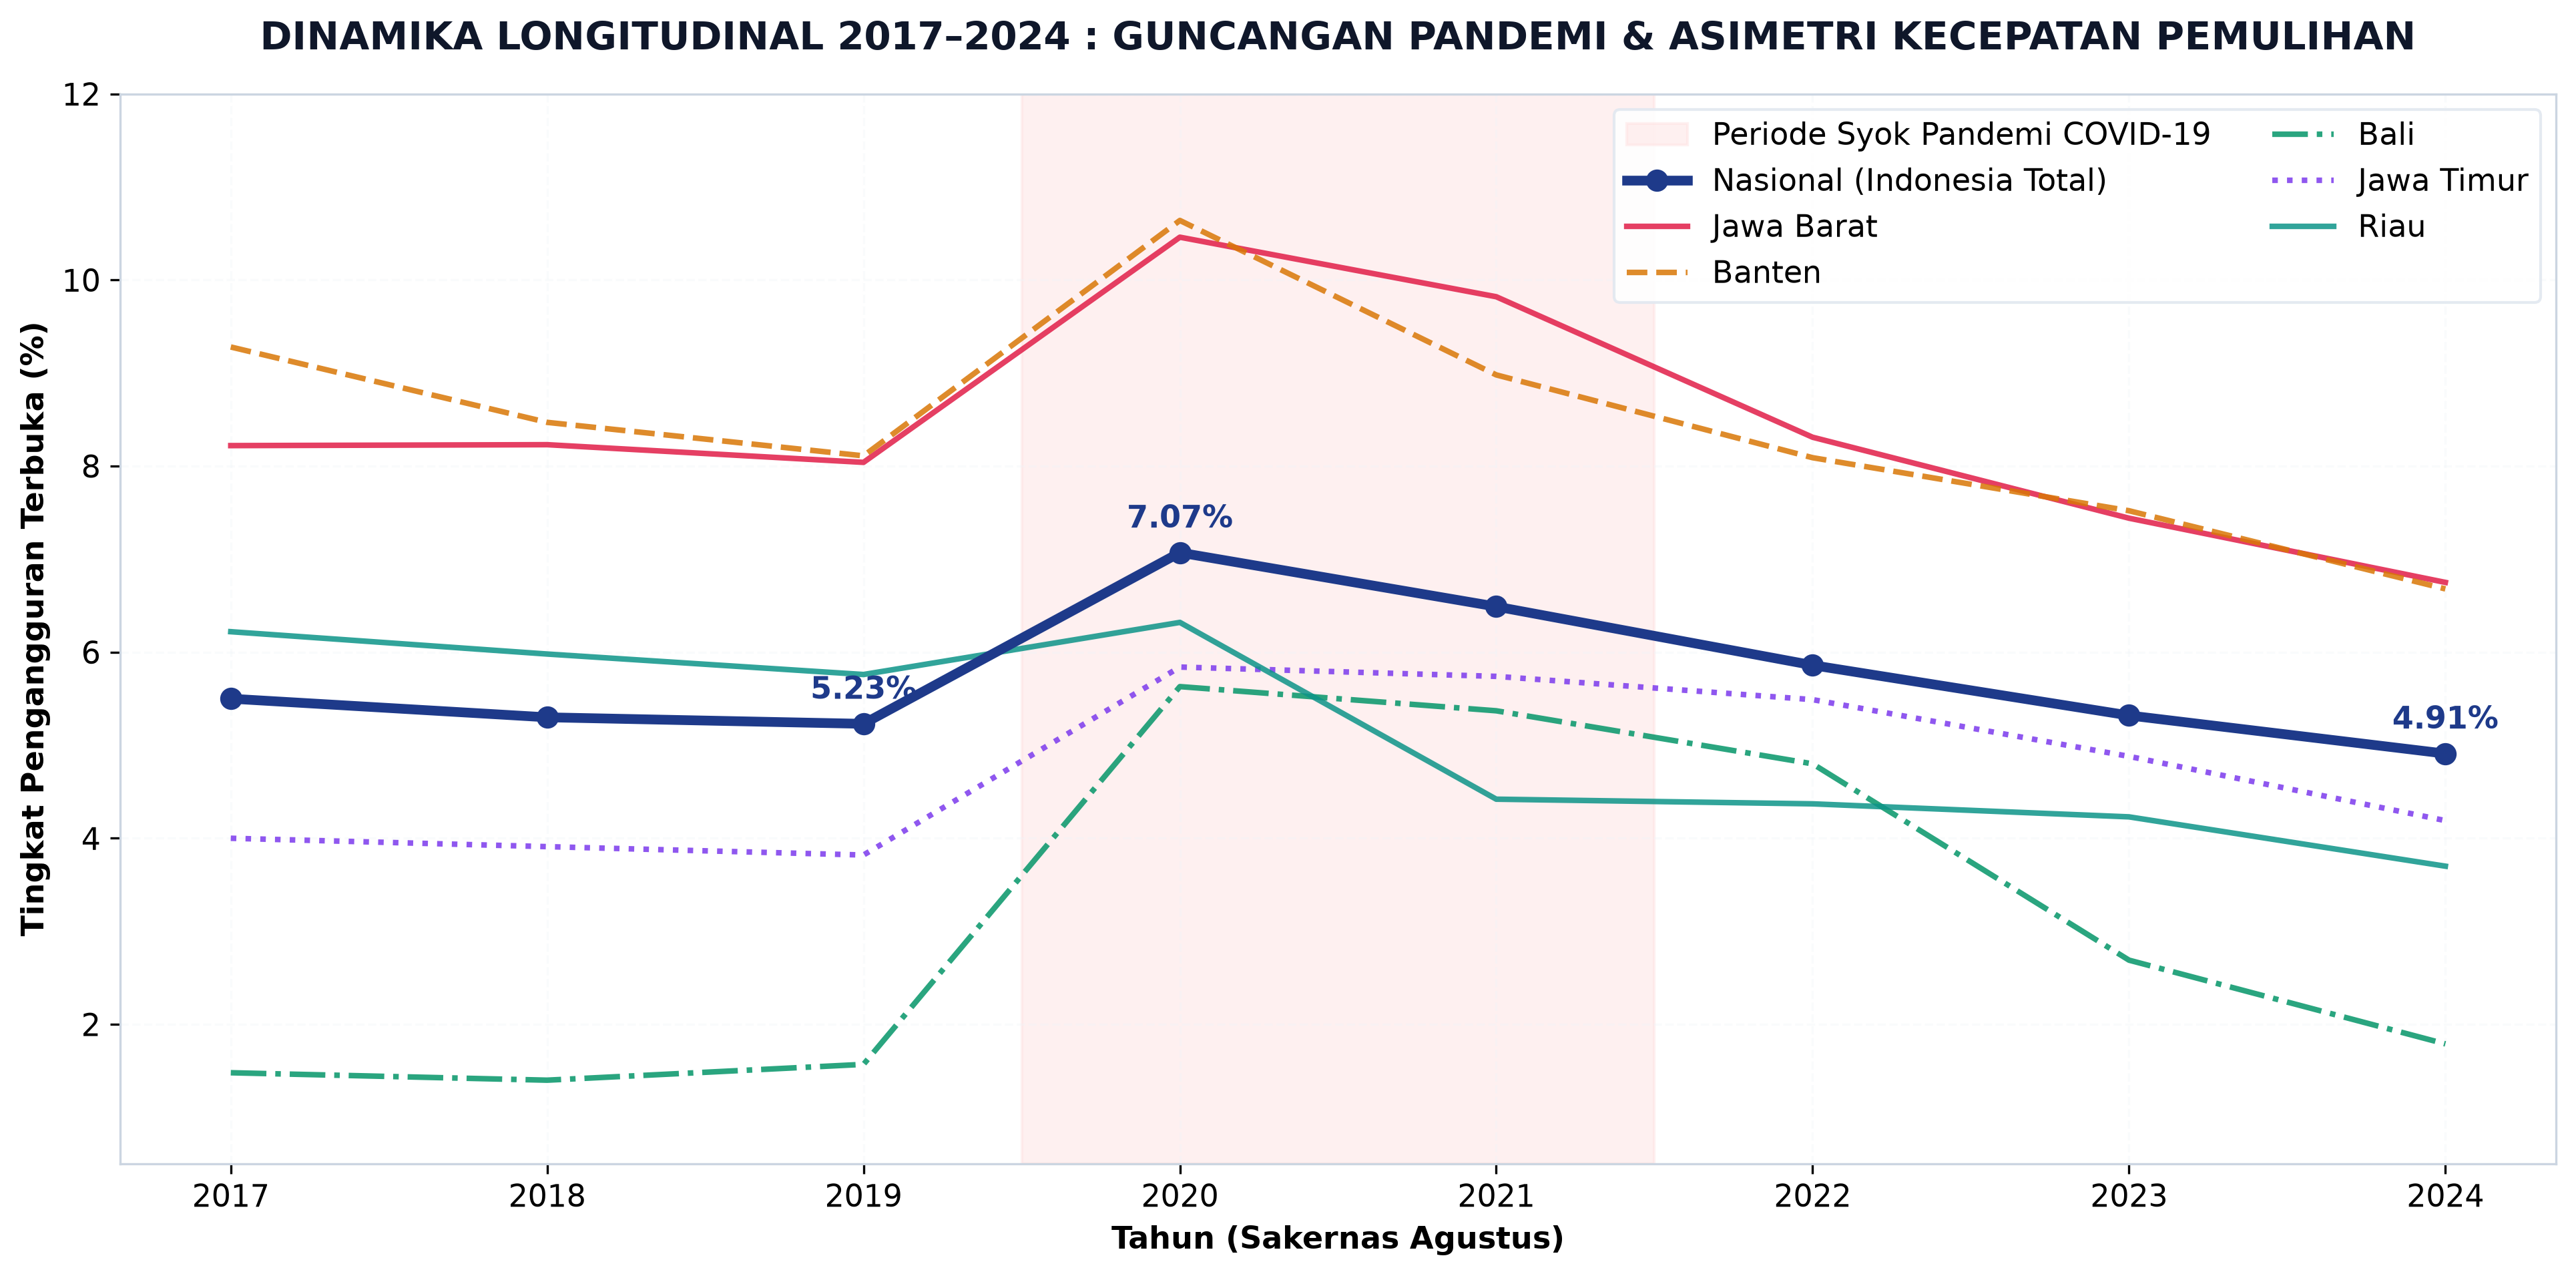

In [7]:
# Grafik 4: Trajektori Longitudinal 2017–2024 — Syok Pandemi dan Dua Kecepatan Pulih
fig, ax = plt.subplots(figsize=(13, 6.5))

years = [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

# National Series
row_nat = df_panel_hist[df_panel_hist["Provinsi"] == "Indonesia"].iloc[0]
vals_nat = [row_nat[f"TPT_{y}"] for y in years]

# Selected Contrast Provinces
prov_samples = {
    "Jawa Barat": (COLOR_CORAL, "-"),
    "Banten": (COLOR_AMBER, "--"),
    "Bali": ("#059669", "-."),
    "Jawa Timur": ("#7C3AED", ":"),
    "Riau": (COLOR_TEAL, "-")
}

# Plot Background Shading for COVID-19 Shock
ax.axvspan(2019.5, 2021.5, color="#FEE2E2", alpha=0.5, label="Periode Syok Pandemi COVID-19")

# Plot National Bold Line
ax.plot(years, vals_nat, color=COLOR_NAVY, linewidth=3.5, marker="o", markersize=7, zorder=6, label="Nasional (Indonesia Total)")
for y, v in zip([2019, 2020, 2024], [5.23, 7.07, 4.91]):
    ax.annotate(f"{v:.2f}%", (y, v), textcoords="offset points", xytext=(0, 9), ha="center", weight="bold", color=COLOR_NAVY)

# Plot Provincial Lines
for prov, (color, ls) in prov_samples.items():
    row_p = df_panel_hist[df_panel_hist["Provinsi"] == prov].iloc[0]
    vals_p = [row_p[f"TPT_{y}"] for y in years]
    ax.plot(years, vals_p, color=color, linestyle=ls, linewidth=2.0, alpha=0.85, label=prov)

ax.set_xticks(years)
ax.set_ylabel("Tingkat Pengangguran Terbuka (%)", weight="bold")
ax.set_xlabel("Tahun (Sakernas Agustus)", weight="bold")
ax.set_title("DINAMIKA LONGITUDINAL 2017–2024 : GUNCANGAN PANDEMI & ASIMETRI KECEPATAN PEMULIHAN", 
             fontsize=14, weight="bold", color=COLOR_TEXT, pad=16)

ax.grid(True, alpha=0.4)
ax.set_ylim(0.5, 12)
ax.legend(loc="upper right", frameon=True, framealpha=0.9, edgecolor="#E2E8F0", ncol=2)

plt.tight_layout()
fig.savefig(CHARTS_DIR / "04_trajektori_pemulihan_longitudinal.svg", format="svg", bbox_inches="tight")
fig.savefig(CHARTS_DIR / "04_trajektori_pemulihan_longitudinal.png", dpi=300, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(CHARTS_DIR / "04_trajektori_pemulihan_longitudinal.png")))


## Bab 5: Turning Insight into Opportunity : Tipologi 3 Klaster & Solusi Kebijakan Terarah

Berdasarkan seluruh bukti empiris yang diuraikan pada Bab 1 hingga Bab 4, satu kesimpulan kebijakan menjadi mutlak: **pendekatan penanggulangan pengangguran yang seragam (one-size-fits-all) telah usang dan gagal menjawab akar persoalan daerah**.

Untuk mengubah wawasan analitis menjadi peluang pemerataan kerja nyata (*Turning Insight into Opportunity*), dilakukan pemodelan klasterisasi K-Means berbasis 4 dimensi objektif: TPT Total 2024, Rasio Mismatch Pendidikan Terdidik, Tingkat Informalitas, dan Rata-rata Upah. Model ini menghasilkan 3 tipologi pasar kerja yang kokoh secara statistik (skor Silhouette = 0,441).

### Arsitektur Tiga Klaster & Matriks Solusi Kebijakan:

#### 1. Klaster 1: Urban-Industrial Trap (8 Provinsi)
* **Wilayah:** DKI Jakarta, Jawa Barat, Banten, Kepulauan Riau, Kalimantan Timur, Maluku, Papua, Papua Barat Daya.
* **Karakteristik Empiris:** TPT tinggi (rata-rata 6,58%), serapan formal tinggi (56,8%), upah tinggi (Rp3,85 juta), namun pengangguran terdidik (SMK dan Sarjana) sangat menumpuk.
* **Intervensi Peluang:**
  * *Revitalisasi Vokasi Sistem Ganda (Dual-System Apprenticeship):* Mewajibkan integrasi kurikulum bersama industri manufaktur dan IT (*curriculum co-creation*), di mana 50% masa studi dihabiskan di pabrik/perusahaan.
  * *Insentif Pajak Superdeduction:* Memberikan potongan pajak penghasilan hingga 200% bagi industri yang mempekerjakan lulusan baru secara permanen dengan upah layak.

#### 2. Klaster 2: Agraris-Informal Shelter (18 Provinsi)
* **Wilayah:** Nusa Tenggara Timur, Nusa Tenggara Barat, Sulawesi Barat, Sulawesi Tengah, Gorontalo, Lampung, Bengkulu, Papua Pegunungan, Papua Tengah, Papua Selatan, dll.
* **Karakteristik Empiris:** TPT rendah semu (rata-rata 2,82%), informalitas ekstrem (rata-rata 75,4%), upah rendah (Rp2,62 juta), didominasi setengah penganggur di sektor pertanian subsisten.
* **Intervensi Peluang:**
  * *Hilirisasi Komoditas Lokal Berbasis UMKM:* Membangun sentra pengolahan hasil panen dan perikanan di tingkat kabupaten untuk mentransformasi petani gurem menjadi pekerja semi-formal bernilai tambah.
  * *Jaring Pengaman Formalisasi Ketenagakerjaan:* Subsidi iuran kepesertaan BPJS Ketenagakerjaan bagi pekerja sektor informal rentan agar terlindungi dari risiko kecelakaan dan hari tua.

#### 3. Klaster 3: Transisi Berimbang (12 Provinsi)
* **Wilayah:** Jawa Tengah, Jawa Timur, DI Yogyakarta, Bali, Sumatera Utara, Sumatera Barat, Sumatera Selatan, Jambi, Riau, Kalimantan Barat, Kalimantan Tengah, Kalimantan Selatan.
* **Karakteristik Empiris:** TPT moderat (rata-rata 4,52%), struktur ekonomi terdiversifikasi, informalitas seimbang (52,6%), upah menengah (Rp2,88 juta).
* **Intervensi Peluang:**
  * *Youth Creative-Tech Hub & Inkubasi Digital:* Fasilitasi ruang kerja bersama dan sertifikasi keterampilan digital di kota-kota sekunder.
  * *Kredit Usaha Rakyat (KUR) Klaster:* Permodalan lunak berbunga rendah bagi wirausaha rintisan pemuda di sektor jasa kreatif dan agritech.


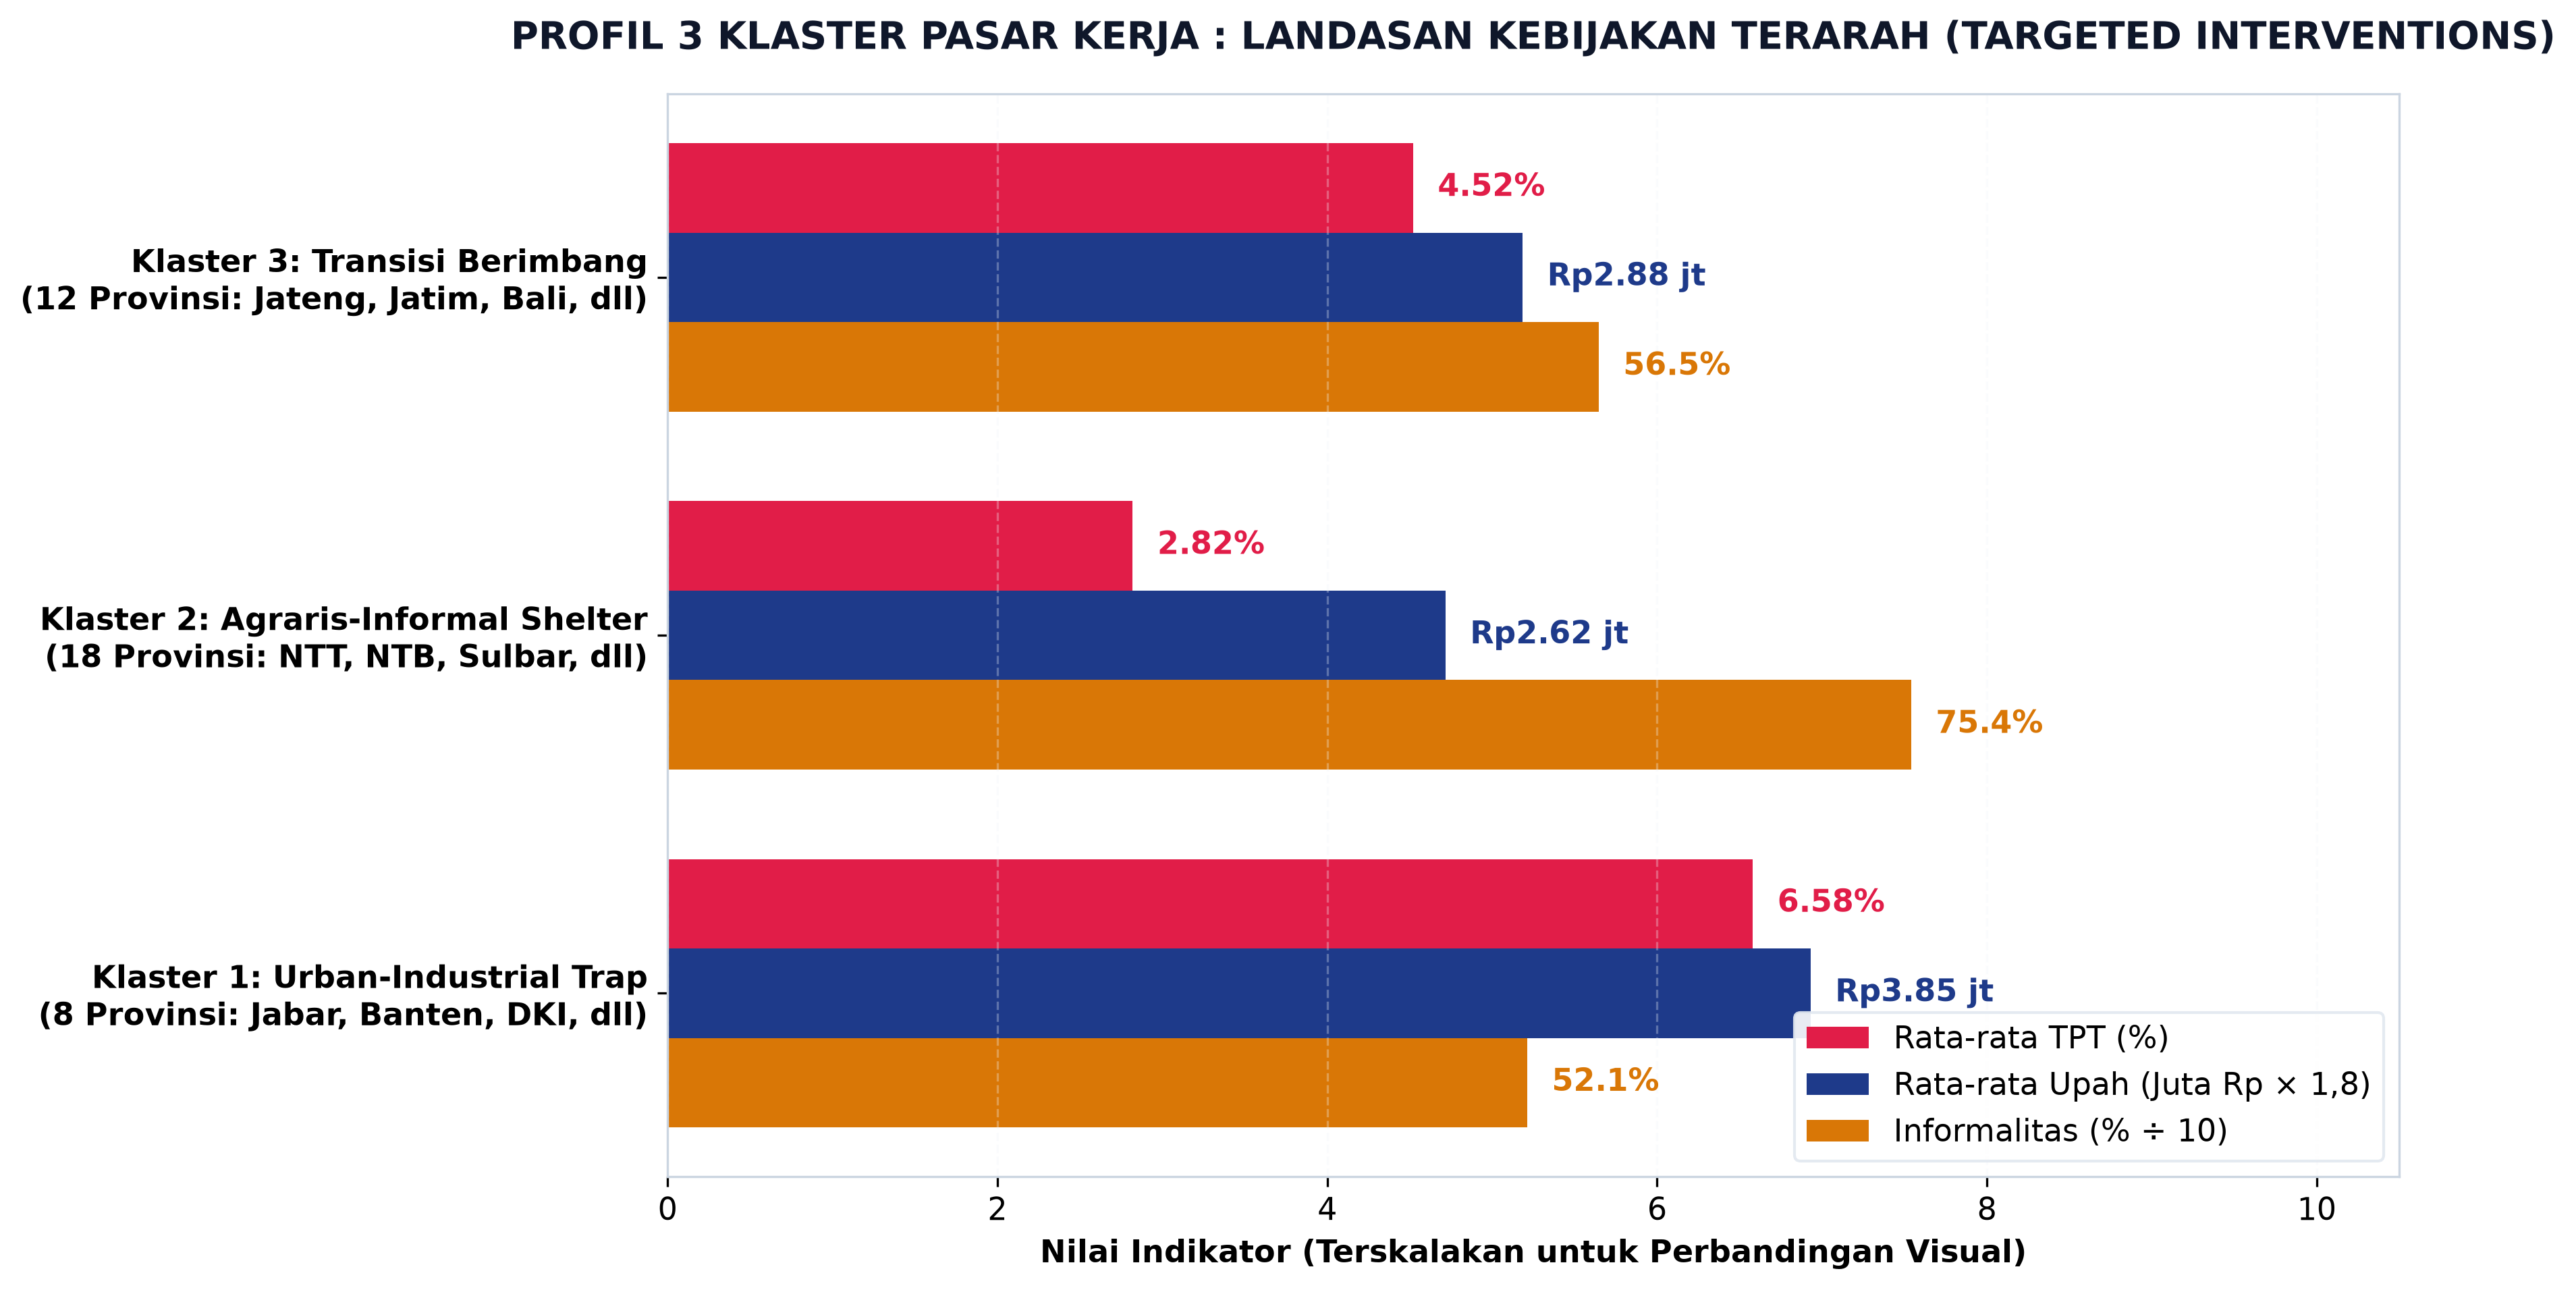

In [8]:
# Grafik 5: Arsitektur Profil 3 Klaster Ketenagakerjaan Daerah
fig, ax = plt.subplots(figsize=(12, 6.5))

klaster_names = [
    "Klaster 1: Urban-Industrial Trap\n(8 Provinsi: Jabar, Banten, DKI, dll)",
    "Klaster 2: Agraris-Informal Shelter\n(18 Provinsi: NTT, NTB, Sulbar, dll)",
    "Klaster 3: Transisi Berimbang\n(12 Provinsi: Jateng, Jatim, Bali, dll)"
]

# Metrics per cluster from KMeans results
avg_tpt = [6.58, 2.82, 4.52]
avg_inf = [52.12, 75.40, 56.45]
avg_wage_juta = [3.85, 2.62, 2.88]

y = np.arange(len(klaster_names))
height = 0.25

# Bar 1: TPT
rects1 = ax.barh(y + height, avg_tpt, height, label="Rata-rata TPT (%)", color=COLOR_CORAL, edgecolor="none")
# Bar 2: Upah (scaled for display: multiplied by 2 so 3.85 jt -> 7.7 for chart balance)
rects2 = ax.barh(y, [w * 1.8 for w in avg_wage_juta], height, label="Rata-rata Upah (Juta Rp × 1,8)", color=COLOR_NAVY, edgecolor="none")
# Bar 3: Informalitas (scaled down by 10 for bar chart)
rects3 = ax.barh(y - height, [inf / 10 for inf in avg_inf], height, label="Informalitas (% ÷ 10)", color=COLOR_AMBER, edgecolor="none")

ax.set_yticks(y)
ax.set_yticklabels(klaster_names, weight="bold")
ax.set_xlabel("Nilai Indikator (Terskalakan untuk Perbandingan Visual)", weight="bold")
ax.set_title("PROFIL 3 KLASTER PASAR KERJA : LANDASAN KEBIJAKAN TERARAH (TARGETED INTERVENTIONS)", 
             fontsize=13.5, weight="bold", color=COLOR_TEXT, pad=16)

# Value annotations on bars
for bar, raw_val in zip(rects1, avg_tpt):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height()/2, f"{raw_val:.2f}%", va="center", weight="bold", color=COLOR_CORAL)

for bar, raw_val in zip(rects2, avg_wage_juta):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height()/2, f"Rp{raw_val:.2f} jt", va="center", weight="bold", color=COLOR_NAVY)

for bar, raw_val in zip(rects3, avg_inf):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height()/2, f"{raw_val:.1f}%", va="center", weight="bold", color=COLOR_AMBER)

ax.grid(axis="x", alpha=0.3)
ax.set_xlim(0, 10.5)
ax.legend(loc="lower right", frameon=True, framealpha=0.9, edgecolor="#E2E8F0")

plt.tight_layout()
fig.savefig(CHARTS_DIR / "05_profil_tiga_klaster_ketenagakerjaan.svg", format="svg", bbox_inches="tight")
fig.savefig(CHARTS_DIR / "05_profil_tiga_klaster_ketenagakerjaan.png", dpi=300, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(CHARTS_DIR / "05_profil_tiga_klaster_ketenagakerjaan.png")))


### Sinergi Ekosistem Stakeholder : Kerangka Aksi Multi-Aktor (A.K.S.I.)

Implementasi intervensi 3 klaster pasar kerja tidak dapat dibebankan pada satu kementerian semata. Kerangka kerja NEXUS digerakkan melalui orkestrasi 4 pilar pemangku kepentingan (*multi-stakeholder governance*):
1. **Pilar Regulasi (Pemerintah Pusat & Kementerian Terkait):** Kementerian PPN/Bappenas, Kemnaker, Kemenperin, dan Kemenkeu bertindak sebagai regulator makro, mengawal target RPJMN 2029 (5,40 juta lapangan kerja), memfasilitasi insentif *Super-Tax Deduction 200%*, dan mengalokasikan subsidi jaring pengaman jaminan sosial.
2. **Pilar Industri (Dunia Usaha & Asosiasi Industri):** KADIN, APINDO, dan korporasi mitra membuka kuota magang industri berupah layak, menyerap 1,85 juta tenaga kerja formal, dan menjadi instruktur praktisi dalam kurikulum kejuruan terakreditasi.
3. **Pilar Proteksi & Modal (Lembaga Pembiayaan & Jaminan Sosial):** BPJS Ketenagakerjaan dan Bank Himbara penyalur KUR memberikan subsidi iuran JKK/JKM bagi 3,5 juta pekerja rentan/informal serta menyalurkan pembiayaan wirausaha muda tanpa agunan tambahan.
4. **Pilar Teritorial (Pemerintah Daerah & Balai Vokasi):** Dinas Tenaga Kerja Provinsi/Kab-Kota bersama SMK, politeknik, dan BLKI mengoperasikan dashboard *Early Warning IKKD* di 45 kab/kota prioritas, mengharmonisasikan upah minimum lintas batas, dan menerapkan kurikulum modular 50% teori : 50% industri.


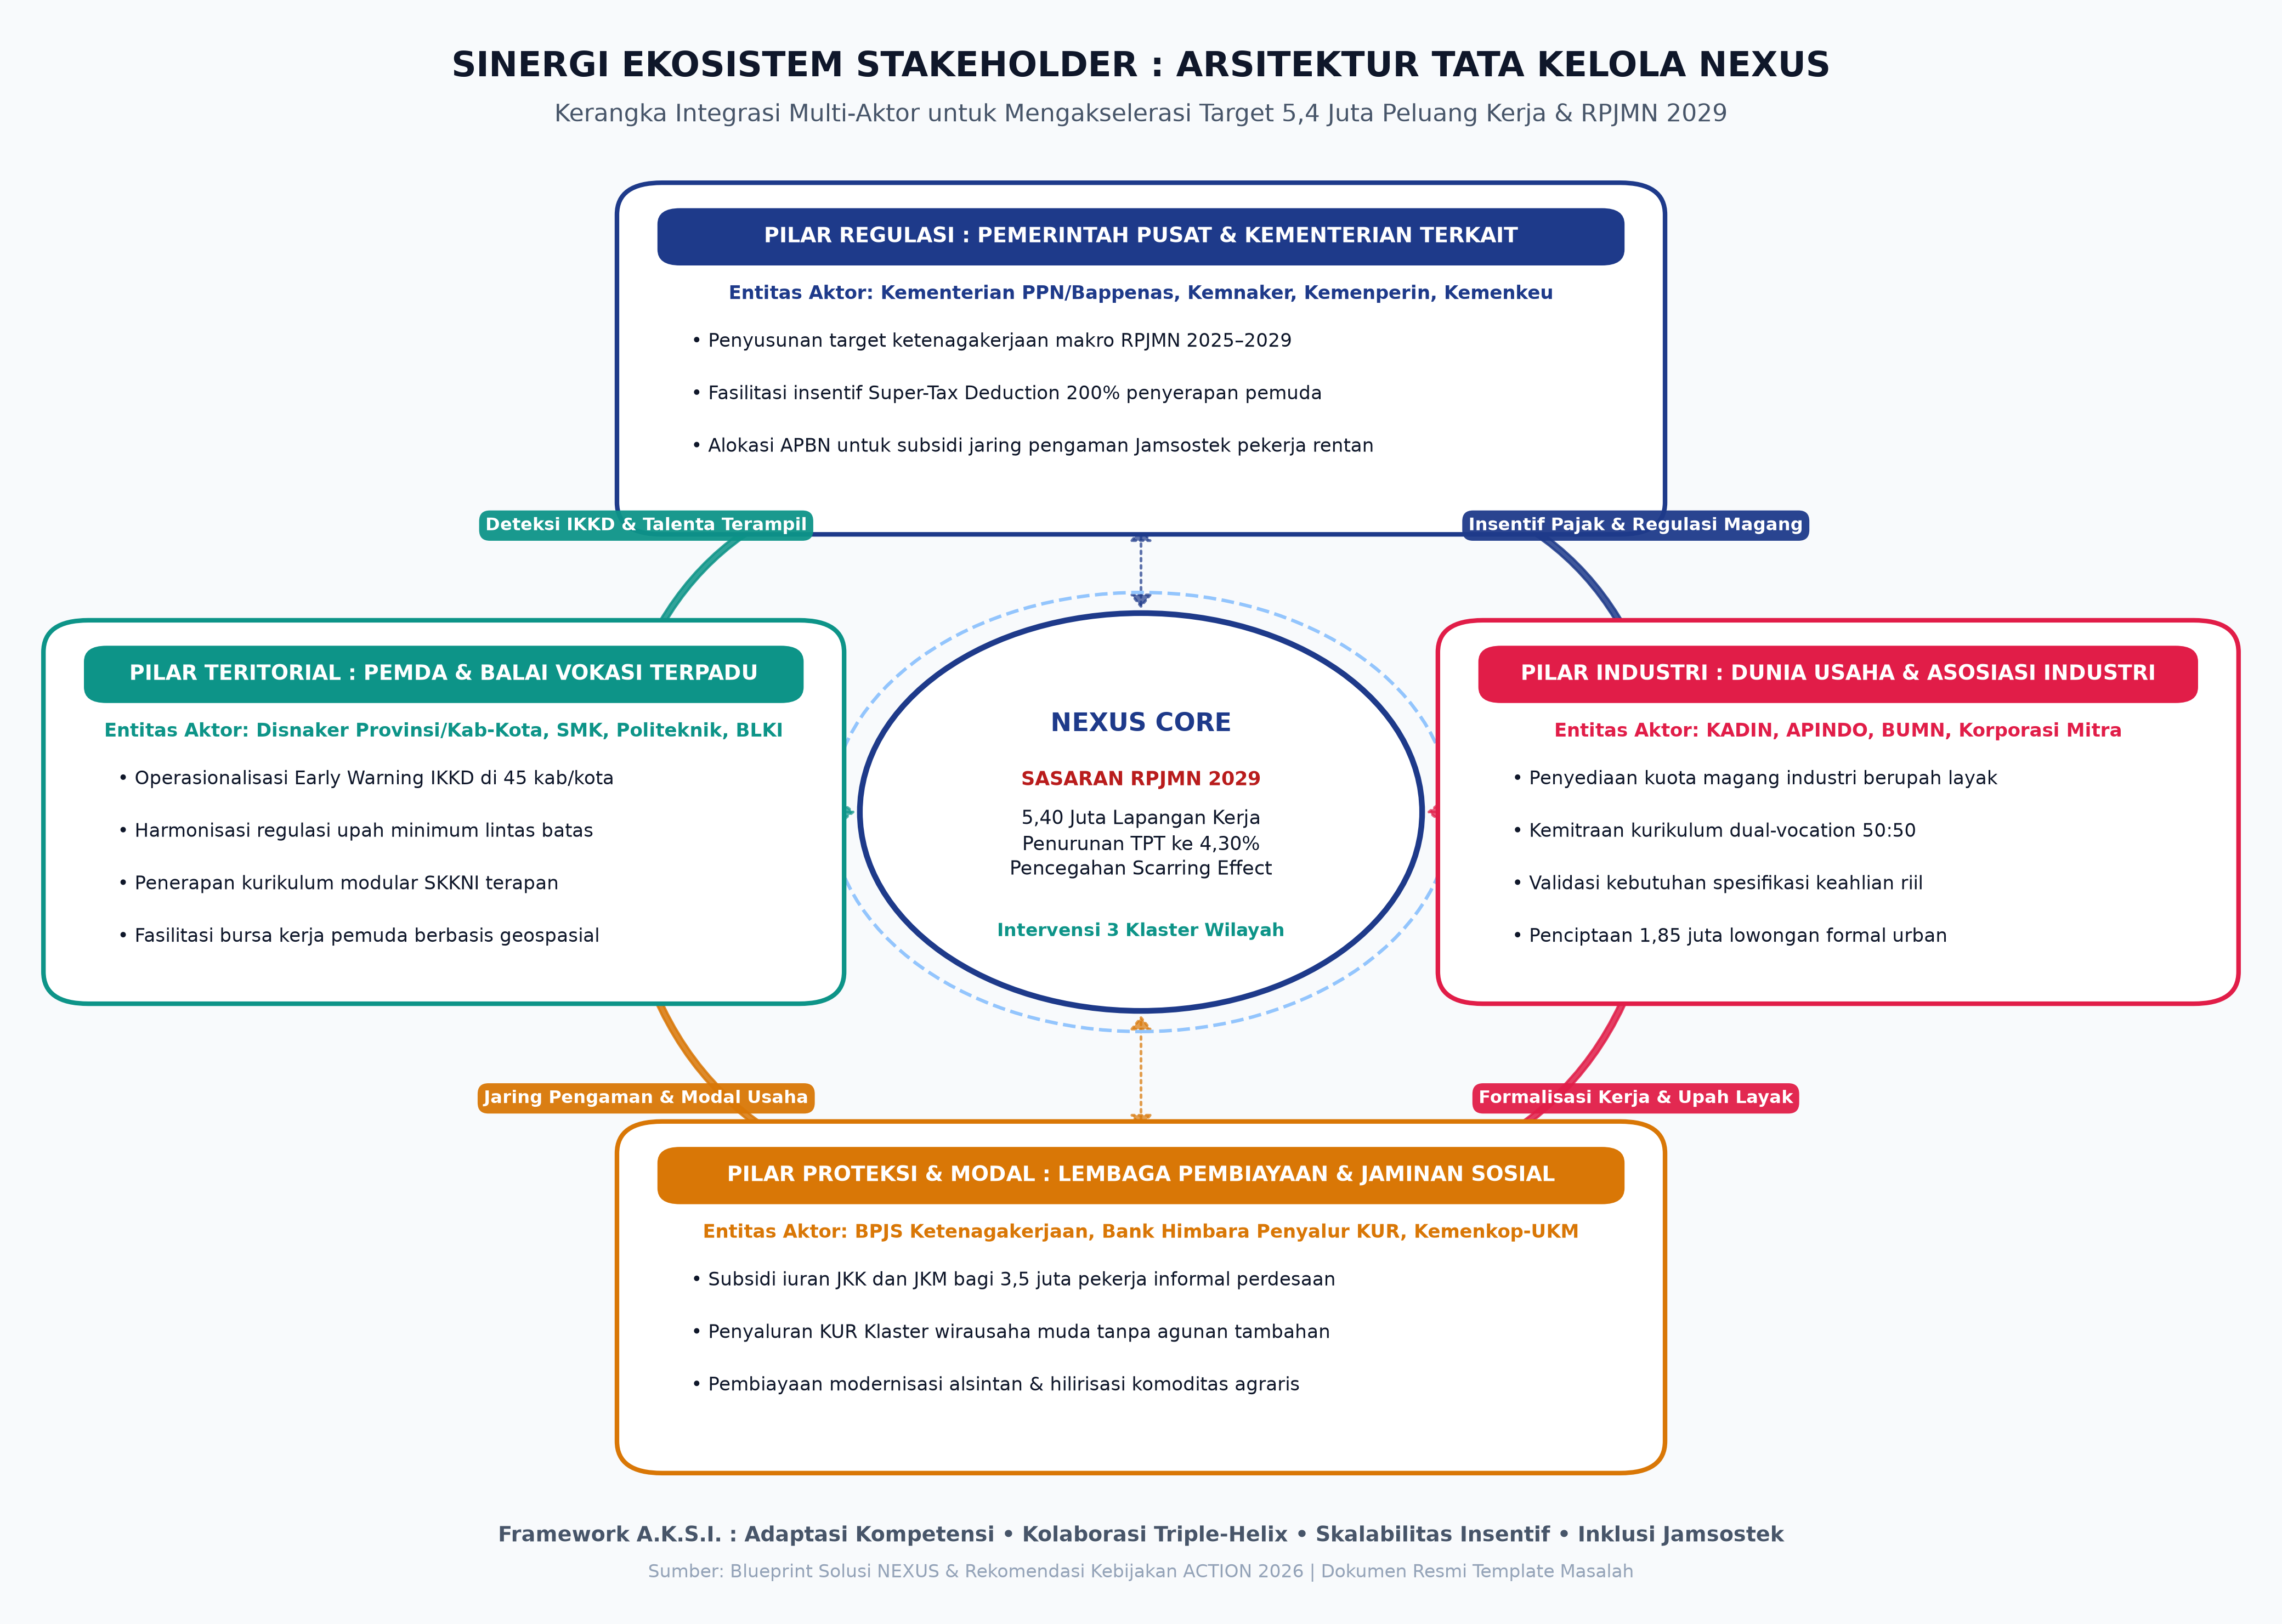

In [9]:
# Grafik 6: Sinergi Ekosistem Stakeholder — Arsitektur Tata Kelola NEXUS
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(14, 10), facecolor="#F8FAFC")
ax.set_facecolor("#F8FAFC")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

NAVY = "#1E3A8A"
TEAL = "#0D9488"
CORAL = "#E11D48"
AMBER = "#D97706"
SLATE = "#475569"
TEXT_MAIN = "#0F172A"

# 1. Header
ax.text(50, 96.8, "SINERGI EKOSISTEM STAKEHOLDER : ARSITEKTUR TATA KELOLA NEXUS",
        ha="center", va="center", fontsize=15, weight="bold", color=TEXT_MAIN)
ax.text(50, 93.8, "Kerangka Integrasi Multi-Aktor untuk Mengakselerasi Target 5,4 Juta Peluang Kerja & RPJMN 2029",
        ha="center", va="center", fontsize=10.5, color=SLATE)

# 2. Central Hub
center_circle = patches.Circle((50, 50), 12.5, facecolor="#FFFFFF", edgecolor=NAVY, linewidth=2.5, zorder=3)
ax.add_patch(center_circle)
center_glow = patches.Circle((50, 50), 13.8, facecolor="none", edgecolor="#93C5FD", linewidth=1.5, linestyle="--", zorder=2)
ax.add_patch(center_glow)

ax.text(50, 55.5, "NEXUS CORE", ha="center", va="center", fontsize=11, weight="bold", color=NAVY, zorder=4)
ax.text(50, 52.0, "SASARAN RPJMN 2029", ha="center", va="center", fontsize=8.5, weight="bold", color="#B91C1C", zorder=4)
ax.text(50, 48.0, "5,40 Juta Lapangan Kerja\nPenurunan TPT ke 4,30%\nPencegahan Scarring Effect", 
        ha="center", va="center", fontsize=8.5, color=TEXT_MAIN, zorder=4, linespacing=1.3)
ax.text(50, 42.5, "Intervensi 3 Klaster Wilayah", ha="center", va="center", fontsize=8, weight="bold", color=TEAL, zorder=4)

def draw_card(cx, cy, w, h, title, actors, roles, accent_color, tag_badge):
    box = patches.FancyBboxPatch((cx - w/2, cy - h/2), w, h,
                                 boxstyle="round,pad=0.8,rounding_size=2.0",
                                 facecolor="#FFFFFF", edgecolor=accent_color, linewidth=2.0, zorder=3)
    ax.add_patch(box)
    
    badge = patches.FancyBboxPatch((cx - w/2 + 1.2, cy + h/2 - 4.2), w - 2.4, 3.2,
                                   boxstyle="round,pad=0.2,rounding_size=1.0",
                                   facecolor=accent_color, edgecolor="none", zorder=4)
    ax.add_patch(badge)
    ax.text(cx, cy + h/2 - 2.6, f"{tag_badge} : {title.upper()}",
            ha="center", va="center", fontsize=9.2, weight="bold", color="#FFFFFF", zorder=5)
    
    ax.text(cx, cy + h/2 - 6.2, f"Entitas Aktor: {actors}",
            ha="center", va="center", fontsize=8.2, weight="bold", color=accent_color, zorder=4)
    
    start_y = cy + h/2 - 9.2
    for i, role in enumerate(roles):
        ax.text(cx - w/2 + 2.5, start_y - (i * 3.3), f"• {role}",
                ha="left", va="center", fontsize=8.2, color=TEXT_MAIN, zorder=4)

# 4 Cards
draw_card(50, 78.5, 45, 20.5,
          "Pemerintah Pusat & Kementerian Terkait",
          "Kementerian PPN/Bappenas, Kemnaker, Kemenperin, Kemenkeu",
          ["Penyusunan target ketenagakerjaan makro RPJMN 2025–2029",
           "Fasilitasi insentif Super-Tax Deduction 200% penyerapan pemuda",
           "Alokasi APBN untuk subsidi jaring pengaman Jamsostek pekerja rentan"],
          NAVY, "PILAR REGULASI")

draw_card(81, 50, 34, 22.5,
          "Dunia Usaha & Asosiasi Industri",
          "KADIN, APINDO, BUMN, Korporasi Mitra",
          ["Penyediaan kuota magang industri berupah layak",
           "Kemitraan kurikulum dual-vocation 50:50",
           "Validasi kebutuhan spesifikasi keahlian riil",
           "Penciptaan 1,85 juta lowongan formal urban"],
          CORAL, "PILAR INDUSTRI")

draw_card(50, 19.5, 45, 20.5,
          "Lembaga Pembiayaan & Jaminan Sosial",
          "BPJS Ketenagakerjaan, Bank Himbara Penyalur KUR, Kemenkop-UKM",
          ["Subsidi iuran JKK dan JKM bagi 3,5 juta pekerja informal perdesaan",
           "Penyaluran KUR Klaster wirausaha muda tanpa agunan tambahan",
           "Pembiayaan modernisasi alsintan & hilirisasi komoditas agraris"],
          AMBER, "PILAR PROTEKSI & MODAL")

draw_card(19, 50, 34, 22.5,
          "Pemda & Balai Vokasi Terpadu",
          "Disnaker Provinsi/Kab-Kota, SMK, Politeknik, BLKI",
          ["Operasionalisasi Early Warning IKKD di 45 kab/kota",
           "Harmonisasi regulasi upah minimum lintas batas",
           "Penerapan kurikulum modular SKKNI terapan",
           "Fasilitasi bursa kerja pemuda berbasis geospasial"],
          TEAL, "PILAR TERITORIAL")

# Curved Connecting Arrows
def draw_curved_arrow(x1, y1, x2, y2, rad, color):
    arrow = patches.FancyArrowPatch((x1, y1), (x2, y2),
                                    connectionstyle=f"arc3,rad={rad}",
                                    arrowstyle="Simple,tail_width=2.5,head_width=9,head_length=9",
                                    color=color, alpha=0.85, zorder=2)
    ax.add_patch(arrow)

draw_curved_arrow(64, 70, 72, 60, -0.22, NAVY)
draw_curved_arrow(72, 40, 64, 28, -0.22, CORAL)
draw_curved_arrow(36, 28, 28, 40, -0.22, AMBER)
draw_curved_arrow(28, 60, 36, 70, -0.22, TEAL)

# Synergy Flow Badges
def draw_flow_badge(x, y, text, color):
    ax.text(x, y, text, ha="center", va="center", fontsize=7.8, weight="bold", color="#FFFFFF",
            bbox=dict(boxstyle="round,pad=0.35,rounding_size=0.6", facecolor=color, edgecolor="none", alpha=0.95),
            zorder=6)

draw_flow_badge(72, 68, "Insentif Pajak & Regulasi Magang", NAVY)
draw_flow_badge(72, 32, "Formalisasi Kerja & Upah Layak", CORAL)
draw_flow_badge(28, 32, "Jaring Pengaman & Modal Usaha", AMBER)
draw_flow_badge(28, 68, "Deteksi IKKD & Talenta Terampil", TEAL)

# Bidirectional Radial Links
def draw_radial_link(x1, y1, x2, y2, color):
    line = patches.FancyArrowPatch((x1, y1), (x2, y2),
                                   arrowstyle="<|-|>,head_width=4,head_length=5",
                                   color=color, linewidth=1.2, linestyle=":", alpha=0.7, zorder=1)
    ax.add_patch(line)

draw_radial_link(50, 68.2, 50, 62.5, NAVY)
draw_radial_link(64, 50, 62.5, 50, CORAL)
draw_radial_link(50, 29.8, 50, 37.5, AMBER)
draw_radial_link(36, 50, 37.5, 50, TEAL)

# Bottom Caption
ax.text(50, 4.5, "Framework A.K.S.I. : Adaptasi Kompetensi • Kolaborasi Triple-Helix • Skalabilitas Insentif • Inklusi Jamsostek",
        ha="center", va="center", fontsize=9.2, weight="bold", color=SLATE)
ax.text(50, 2.2, "Sumber: Blueprint Solusi NEXUS & Rekomendasi Kebijakan ACTION 2026 | Dokumen Resmi Template Masalah",
        ha="center", va="center", fontsize=8.0, color="#94A3B8")

plt.tight_layout()
fig.savefig(CHARTS_DIR / "16_sinergi_ekosistem_stakeholder.svg", format="svg", bbox_inches="tight")
fig.savefig(CHARTS_DIR / "16_sinergi_ekosistem_stakeholder.png", dpi=300, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(CHARTS_DIR / "16_sinergi_ekosistem_stakeholder.png")))


## Kesimpulan Akhir & Peta Jalan Indonesia Emas 2045

Melalui rangkaian analisis data yang dipaparkan dalam notebook ini, kita telah membuktikan tiga tesis kunci:
1. Penurunan angka pengangguran terbuka nasional ke level 4,91% tidak boleh dirayakan secara naif, karena beban krisis masih membelenggu generasi muda (17,02%) dan lulusan terdidik (SMK 6,81% dan Universitas 5,33%).
2. Angka pengangguran rendah di daerah pedesaan dan kawasan timur Indonesia adalah ilusi statistik yang didorong oleh tingginya keterpaksaan bekerja di sektor informal rentan (*r = -0,782*).
3. Pemerataan kesempatan kerja hanya dapat terwujud jika pemerintah pusat dan daerah meninggalkan kebijakan seragam, beralih menuju intervensi afirmatif berbasis klaster wilayah (*Urban Link-and-Match, Agrarian Downstreaming, dan Youth Creative Tech*).

Dengan menjadikan wawasan data ini sebagai landasan aksi (*Turning Insight into Opportunity*), Indonesia dapat memastikan bahwa jendela bonus demografi tidak terbuang sia-sia, melainkan bertransformasi menjadi fondasi kemakmuran menuju Indonesia Emas 2045.
